# Quantitative Proteomic Profiling of Differential Extracellular Vesicle (EV) Cargo Uptake by Recipient Osteoblasts

**Academic Context:** Research Mini-Project, Utrecht University
**Experimental Design:** Multiplexed 18-plex TMTpro coupled with metabolic Heavy SILAC MS3 proteomics
**Biological Model:** Differential internalization of prostate carcinoma EV cargo (non-metastatic PC3 vs. metastatic PC3M) by recipient SAOS-2 osteoblasts  

---

### Project Overview

Extracellular vesicles serve as key mediators of cell-to-cell communication, transferring bioactive macromolecular cargo to recipient cells and preparing target microenvironments during tumor progression. A major analytical hurdle in uptake proteomics lies in distinguishing true functional selectivity, where specific cargo molecules are preferentially internalized, from non-specific bulk endocytosis of whole vesicles. 

This repository contains an end-to-end computational framework developed during a research internship at Utrecht University to address this challenge. The project establishes an objective analytical pipeline covering baseline instrumental noise filtering, multi-layered normalization to isolate stoichiometric cargo selectivity from bulk uptake kinetics, and statistical hypothesis testing tailored for small-sample experimental cohorts. Together, these workflows identify high-confidence protein drivers associated with differential vesicle uptake and provide an unsupervised multivariate evaluation of phenotype-specific cargo signatures.

---

### Author, Repository & Licensing

* **Author:** Vladislav Mantsevich
* **Affiliation:** Utrecht University  
* **GitHub Repository:** https://github.com/Dudkanist/ev-uptake-proteomics
* **Contact:** vladmanest@gmail.com

All data processing workflows, analytical scripts, and downstream visualizations were independently conceptualized and executed by the author.

**Open Source License:**  
This code and pipeline are distributed under the terms of the **GNU General Public License v3.0 (GPL-3.0)**. You are free to inspect, run, modify, and redistribute this computational workflow in accordance with the GPL-3.0 provisions. For questions regarding code execution, reproduction of results, or data matrices, please reach out via email.

## 0. Environment Configuration and Dependency Initialization

We import core scientific libraries for numerical processing, multivariate dimensionality reduction, statistical hypothesis testing, and supervised machine learning.

In [1]:
import os
import sys
from pathlib import Path

r_home = Path(sys.prefix) / "lib" / "R"
if "R_HOME" not in os.environ or not Path(os.environ["R_HOME"]).exists():
    os.environ["R_HOME"] = str(r_home)

import rpy2.robjects as ro
from rpy2.robjects import pandas2ri
from rpy2.robjects.conversion import localconverter

In [2]:
import io

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import requests
import seaborn as sns
from scipy import stats
from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler
from statsmodels.stats.multitest import multipletests

## 1. Data Ingestion

We load the primary search export from Proteome Discoverer (`MEK_25_02_label_included.txt`). The raw tabular output includes peptide identifications, isotopic precursor annotations, spectral quality metrics, and continuous 18-plex TMT reporter ion intensities.

In [3]:
file_path = "MEK_25_02_label_included.txt"
df = pd.read_csv(file_path, sep="\t", low_memory=False)
print(
    f"Initial dataset shape: {df.shape[0]} peptide records, {df.shape[1]} metadata/intensity columns"
)
df.head(3)

Initial dataset shape: 88138 peptide records, 61 metadata/intensity columns


,Checked,Confidence,Annotated Sequence,Modifications,Contaminant,Number of Protein Groups,Number of Proteins,Number of PSMs,Master Protein Accessions,Positions in Master Proteins,...,q-Value by Search Engine Sequest HT,PEP by Search Engine Sequest HT,SVM Score by Search Engine Sequest HT,XCorr by Search Engine Sequest HT,PEP,q-Value,Channel Occupancy in Percent,Label,K label,R label
0,False,High,SDYLNTFEFMDK,1xTMTpro [N-Term]; 1xTMTpro [K12],False,1,1,2,O75874,O75874 [389-400],...,0.000029,5.638660e-06,1.29805,4.02,0.000006,0.000038,NaN,light,NaN,NaN
1,False,High,TLQALEFHTVPFQLLAR,1xTMTpro [N-Term],False,1,1,2,Q08380,Q08380 [377-393],...,0.000046,8.212470e-07,1.14519,2.94,0.000004,0.000038,NaN,light,NaN,NaN
2,False,High,QMADGGWGEDFESCEER,1xTMTpro [N-Term]; 1xCarbamidomethyl [C14],False,1,1,2,P48449,P48449 [623-639],...,0.000029,1.298870e-05,1.17893,5.13,0.000015,0.000038,NaN,light,NaN,NaN


| Column Name | Data Type / Example Values | Description & Interpretation |
| --- | --- | --- |
| **`Checked`** | Boolean (`False`) | Internal Proteome Discoverer user checkbox for manual verification. |
| **`Confidence`** | Categorical (`'High'`) | Overall identification confidence level calculated by Percolator. |
| **`Annotated Sequence`** | String (`'SDYLNTFEFMDK'`, etc.) | Amino acid sequence of the identified peptide. |
| **`Modifications`** | String (`1xTMTpro`, etc.) | Post-translational and chemical modifications identified on specific residues. |
| **`Contaminant`** | Boolean (`False`) | Flag identifying known laboratory contaminants (e.g., keratins, trypsin). |
| **`Number of Protein Groups`** | Integer (`0`, `1`) | Number of distinct protein groups to which the peptide sequence is assigned. |
| **`Number of Proteins`** | Integer (`1`, `2`, `3`, etc.) | Number of individual database entries (UniProt IDs) matching this peptide sequence. |
| **`Number of PSMs`** | Integer (`1`, `2`, `7`, etc.) | Peptide-Spectrum Matches: total number of times MS2 spectra matched this peptide. |
| **`Master Protein Accessions`** | String (`'O75874'`, etc.) | UniProt accession ID of the lead representative protein for the protein group. |
| **`Positions in Master Proteins`** | String (`'O75874 [389-400]'`) | Exact residue range coordinates of the peptide within the master protein sequence. |
| **`Modifications in Master Proteins`** | Mixed / Float (`NaN`) | Annotation of sequence-level modifications matched to the master sequence. |
| **`Number of Missed Cleavages`** | Integer (`0`, `1`, `2`) | Number of missed trypsin cleavage sites remaining within the sequence. |
| **`Theo MHplus in Da`** | Float ($\sim 2100\text{--}2700\text{ Da}$) | Theoretical monoisotopic mass of the protonated peptide precursor. |
| **`Abundance F13 XXX Sample`** *(Aggregated)* | Float (`nan`, `0.0`, etc.) | SPS-MS3 TMTpro reporter intensities across boost, empty, SAOS2 control, uptake experimental, and spike reference channels. |
| **`Quan Info`** | String (`'NoQuanValues'`, `NaN`) | Status flag indicating validity of quantitative MS3 measurement in PD. |
| **`Found in Sample F13 [Channel]`** | Categorical (`'High'`, `NaN`) | Discrete detection reliability indicator per channel. |
| **`Sequest HT Search Metrics`** *(Aggregated)* | Categorical / Float | Search engine diagnostic scores, $q$-values, PEP, SVM scores, and XCorr values from Sequest HT. |
| **`PEP`** & **`q-Value`** | Float ($\le 0.01$) | Global consensus posterior error probability and minimal FDR threshold. |
| **`Channel Occupancy in Percent`** | Float ($72.0\text{--}94.0\%$) | Proportion of the 18 TMT channels showing non-zero reporter signal. |
| **`Label`** | Categorical (`'light'`, `'heavy'`) | Metabolic SILAC isotope status (Heavy = vesicular cargo, Light = recipient cells). |
| **`K label`** & **`R label`** | Categorical | Isotope modification tags for deuterated Lysine-D8 and Arginine-10. |
| **`active_channels`** | Integer ($0\text{--}18$) | Custom calculated column counting TMT channels with abundance $> 0$. (Otherwise Nan) |
| **`Peptide Length`** | Integer ($7\text{--}30$) | Custom calculated column for length in amino acids after stripping modifications. |

## 2. Upstream Quality Control (MS1 and MS2 Levels)

Before applying quantitative normalization, we assess data across 4 parameters:
1. **Metabolic Label Ratio**: Proportion of Heavy (vesicular cargo) to Light (recipient SAOS-2 cellular background) peptides.
2. **Contaminant Annotation**: Verification that external contaminants (e.g., keratins, bovine trypsin) were filtered out during database searching.
3. **Peptide Uniqueness**: Frequency of peptide matches mapping uniquely to a single protein vs. shared across homologs.
4. **PSM False Discovery Rate**: Global $q$-value distribution to ensure high-confidence identification thresholds.

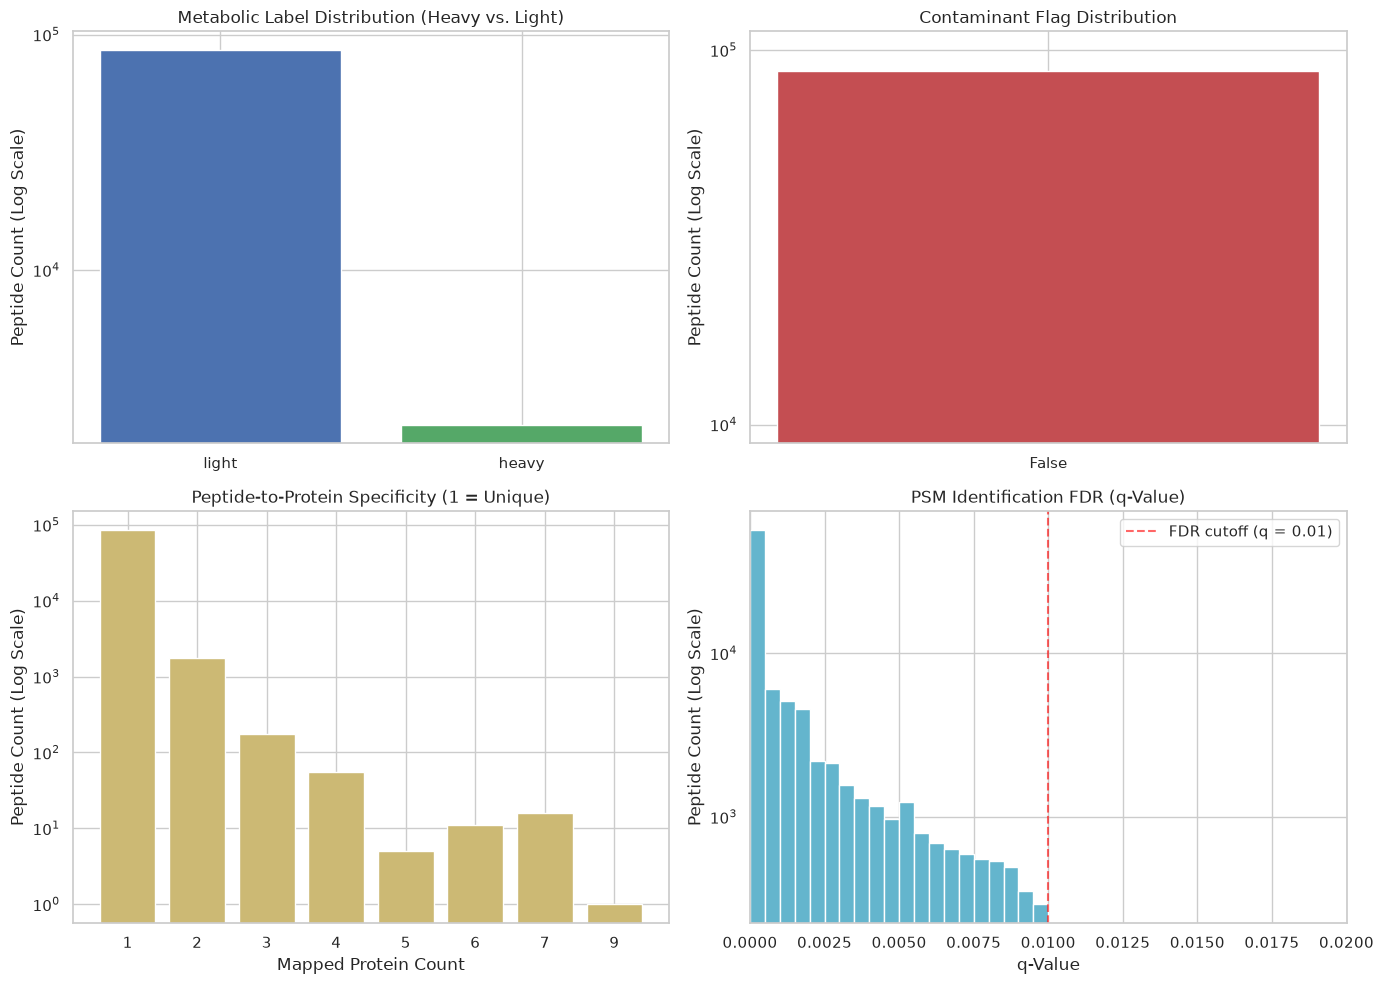

In [4]:
sns.set_theme(style="whitegrid")
fig, axes = plt.subplots(2, 2, figsize=(14, 10))

# Panel 1: Metabolic Label Distribution
label_counts = df["Label"].value_counts(dropna=False)
axes[0, 0].bar(
    label_counts.index.astype(str), label_counts.values, color=["#4C72B0", "#55A868"]
)
axes[0, 0].set_yscale("log")
axes[0, 0].set_title("Metabolic Label Distribution (Heavy vs. Light)")
axes[0, 0].set_ylabel("Peptide Count (Log Scale)")

# Panel 2: Contaminant Identification
contam_counts = df["Contaminant"].value_counts(dropna=False)
axes[0, 1].bar(
    contam_counts.index.astype(str), contam_counts.values, color=["#C44E52", "#8172B2"]
)
axes[0, 1].set_yscale("log")
axes[0, 1].set_title("Contaminant Flag Distribution")
axes[0, 1].set_ylabel("Peptide Count (Log Scale)")

# Panel 3: Peptide-to-Protein Mapping Ratio
prot_counts = df["Number of Proteins"].value_counts().sort_index().head(8)
axes[1, 0].bar(prot_counts.index.astype(str), prot_counts.values, color="#CCB974")
axes[1, 0].set_yscale("log")
axes[1, 0].set_title("Peptide-to-Protein Specificity (1 = Unique)")
axes[1, 0].set_xlabel("Mapped Protein Count")
axes[1, 0].set_ylabel("Peptide Count (Log Scale)")

# Panel 4: PSM Confidence Thresholds (q-value)
q_vals = pd.to_numeric(df["q-Value"], errors="coerce").dropna()
axes[1, 1].hist(q_vals, bins=100, color="#64B5CD", range=(0, 0.05), log=True)
axes[1, 1].axvline(
    0.01,
    color="red",
    linestyle="--",
    linewidth=1.5,
    alpha=0.6,
    label="FDR cutoff (q = 0.01)",
)
axes[1, 1].set_title("PSM Identification FDR (q-Value)")
axes[1, 1].set_xlabel("q-Value")
axes[1, 1].set_ylabel("Peptide Count (Log Scale)")
axes[1, 1].set_xlim(0, 0.02)
axes[1, 1].legend()

plt.tight_layout()
plt.show()

### Baseline Filtering Summary

The table below delineates the input dataset structure at the peptide level prior to abundance filtering.

| QC Metric | Value / Criterion | Peptide Count ($n$) | Share of Pool ($\%$) | Pipeline Status |
| :--- | :--- | :--- | :--- | :--- |
| **Total Identifications** | Raw Proteome Discoverer output | **88,138** | **100.0%** | Raw input cohort |
| **PSM Spectral Confidence** | $q$-value $\le 0.01$ (FDR 1%) | 88,138 | 100.0% | Pre-filtered by search engine |
| **Contaminants** | `Contaminant == False` | 88,138 | 100.0% | Retained post-filtering |
| **Mapping Specificity** | `Number of Proteins == 1` | 86,106 | 97.7% | Strictly unique peptides |
| | `Number of Proteins > 1` | 2,032 | 2.3% | Shared / razor peptides |
| **Metabolic Origin** | `Label == 'light'` (recipient cells) | 85,929 | 97.5% | Background recipient proteome |
| | `Label == 'heavy'` (EV cargo) | 2,209 | 2.5% | Target vesicular proteome |

## 3. Enzymatic Cleavage and Peptide Length Profiling

To verify tryptic digestion efficiency and ensure analytical uniformity between heavy and light pools, we evaluate sequence length distributions.

Sequence length summary metrics:
Total peptides:         88138
Minimum length:         7 aa
Median length:          12.0 aa
Mean length:            13.13 aa
Maximum length:         30 aa


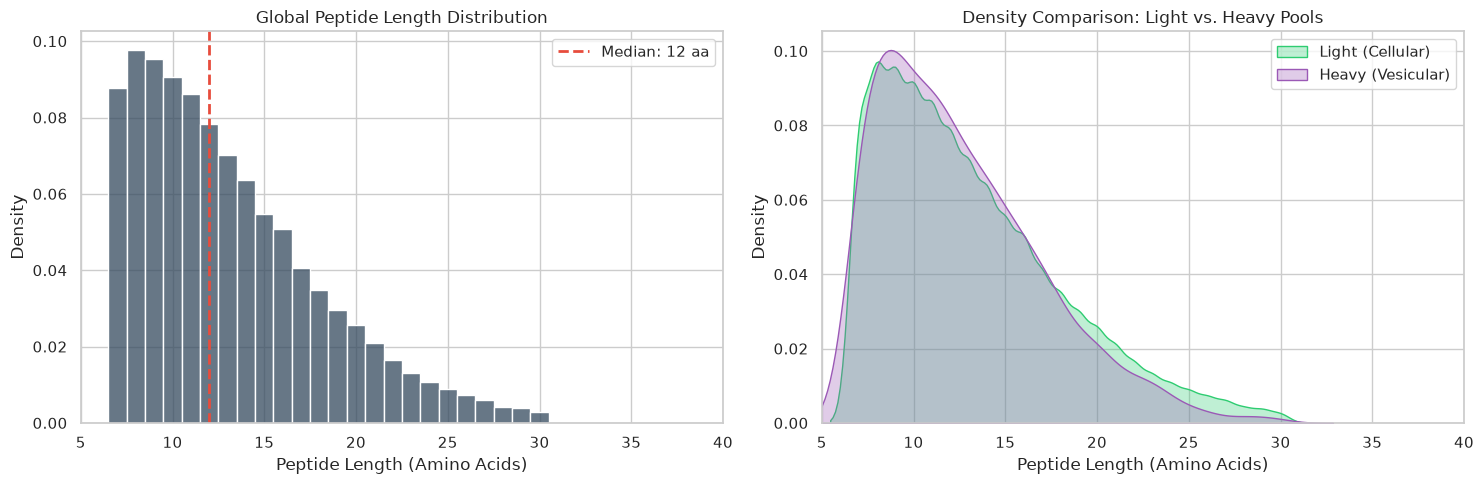

In [5]:
df["Peptide Length"] = df["Annotated Sequence"].apply(len)

stats_all = df["Peptide Length"].describe(percentiles=[0.01, 0.05, 0.5, 0.95, 0.99])
print("=" * 55)
print("Sequence length summary metrics:")
print(f"Total peptides:         {int(stats_all['count'])}")
print(f"Minimum length:         {int(stats_all['min'])} aa")
print(f"Median length:          {stats_all['50%']:.1f} aa")
print(f"Mean length:            {stats_all['mean']:.2f} aa")
print(f"Maximum length:         {int(stats_all['max'])} aa")
print("=" * 55)

fig, axes = plt.subplots(1, 2, figsize=(15, 5))
bins = np.arange(
    df["Peptide Length"].min() - 0.5, min(df["Peptide Length"].max(), 40) + 1.5, 1
)

sns.histplot(
    data=df,
    x="Peptide Length",
    bins=bins,
    color="#34495e",
    ax=axes[0],
    stat="density",
    discrete=True,
)
axes[0].axvline(
    df["Peptide Length"].median(),
    color="#e74c3c",
    linestyle="--",
    linewidth=2,
    label=f"Median: {df['Peptide Length'].median():.0f} aa",
)
axes[0].set_title("Global Peptide Length Distribution")
axes[0].set_xlabel("Peptide Length (Amino Acids)")
axes[0].set_ylabel("Density")
axes[0].set_xlim(5, 40)
axes[0].legend()

sns.kdeplot(
    data=df[df["Label"] == "light"],
    x="Peptide Length",
    color="#2ecc71",
    fill=True,
    alpha=0.3,
    label="Light (Cellular)",
    ax=axes[1],
    common_norm=False,
)
sns.kdeplot(
    data=df[df["Label"] == "heavy"],
    x="Peptide Length",
    color="#9b59b6",
    fill=True,
    alpha=0.3,
    label="Heavy (Vesicular)",
    ax=axes[1],
    common_norm=False,
)
axes[1].set_title("Density Comparison: Light vs. Heavy Pools")
axes[1].set_xlabel("Peptide Length (Amino Acids)")
axes[1].set_ylabel("Density")
axes[1].set_xlim(5, 40)
axes[1].legend()

plt.tight_layout()
plt.show()

## 4. TMT Multiplex Reporter Occupancy Diagnostics

We next evaluate channel occupancy across the 18 TMT reporter channels. Peptides with zero intensity across all channels reflect records identified in MS2 but not selected or quantified at the MS3 level.

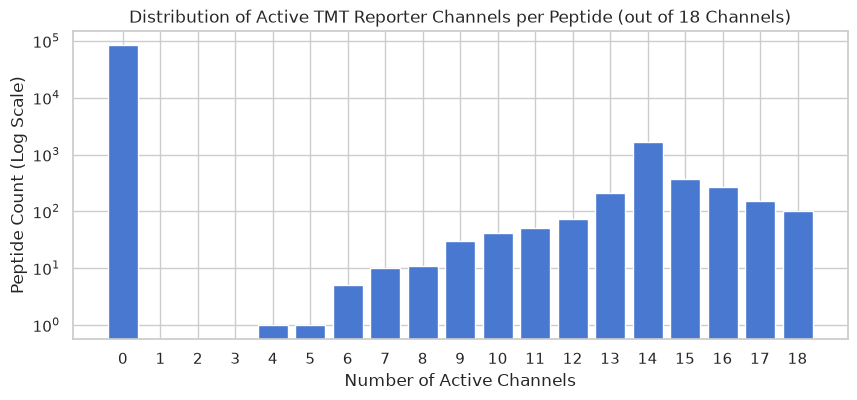

Channel occupancy summary by isotopic label:
       count  median      mean
Label                         
heavy   2209     0.0  6.625170
light  85929     0.0  0.324815


In [6]:
abundance_cols = [c for c in df.columns if c.startswith("Abundance F13")]
df[abundance_cols] = df[abundance_cols].apply(pd.to_numeric, errors="coerce")
df["active_channels"] = (df[abundance_cols] > 0).sum(axis=1)

plt.figure(figsize=(10, 4))
plt.hist(
    df["active_channels"],
    bins=range(20),
    align="left",
    rwidth=0.8,
    color="#4878D0",
    log=True,
)
plt.title(
    "Distribution of Active TMT Reporter Channels per Peptide (out of 18 Channels)"
)
plt.xlabel("Number of Active Channels")
plt.ylabel("Peptide Count (Log Scale)")
plt.xticks(range(19))
plt.show()

print("Channel occupancy summary by isotopic label:")
print(df.groupby("Label")["active_channels"].agg(["count", "median", "mean"]))

## 5. Investigation of Unquantified Heavy Peptides (RTS Duty Cycle Analysis)

Within the target heavy subset ($n = 2,209$), roughly half contain zero reporter intensities across all channels. We inspect the `Quan Info` diagnostic column to determine whether this stems from real-time search (RTS) duty-cycle limits or post-acquisition spectral exclusion.

In [7]:
quan_breakdown = df[df["Label"] == "heavy"]["Quan Info"].value_counts(dropna=False)
print("Quantification status for Heavy peptides:")
print(quan_breakdown)

Quantification status for Heavy peptides:
Quan Info
NoQuanValues        1175
NaN                 1018
ExcludedByMethod      16
Name: count, dtype: int64


| Status Flag | Peptide Count ($n$) | Share of Heavy ($\%$) | Analytical Cause |
| :--- | :--- | :--- | :--- |
| **NaN (Passed)** | 1,018 | 46.1% | Valid SPS-MS3 scan passed all filtering criteria. |
| **NoQuanValues** | 1,175 | 53.2% | Precursor confirmed at MS2, but MS3 was not triggered (duty-cycle limitations & stringent real-time peptide identification criteria). |
| **ExcludedByMethod** | 16 | 0.7% | MS3 scan acquired but rejected due to high co-isolation or low SPS match. |

Spectral exclusion due to poor scan quality accounts for only $0.7\%$ of heavy peptides. The primary attrition factor was instrument duty-cycle constraints during real-time triggering.

## 6. Quantifiable Heavy Peptide Cohort

We isolate the 1,018 quantifiable heavy peptides (`active_channels > 0`) and examine their channel occupancy across replicates.

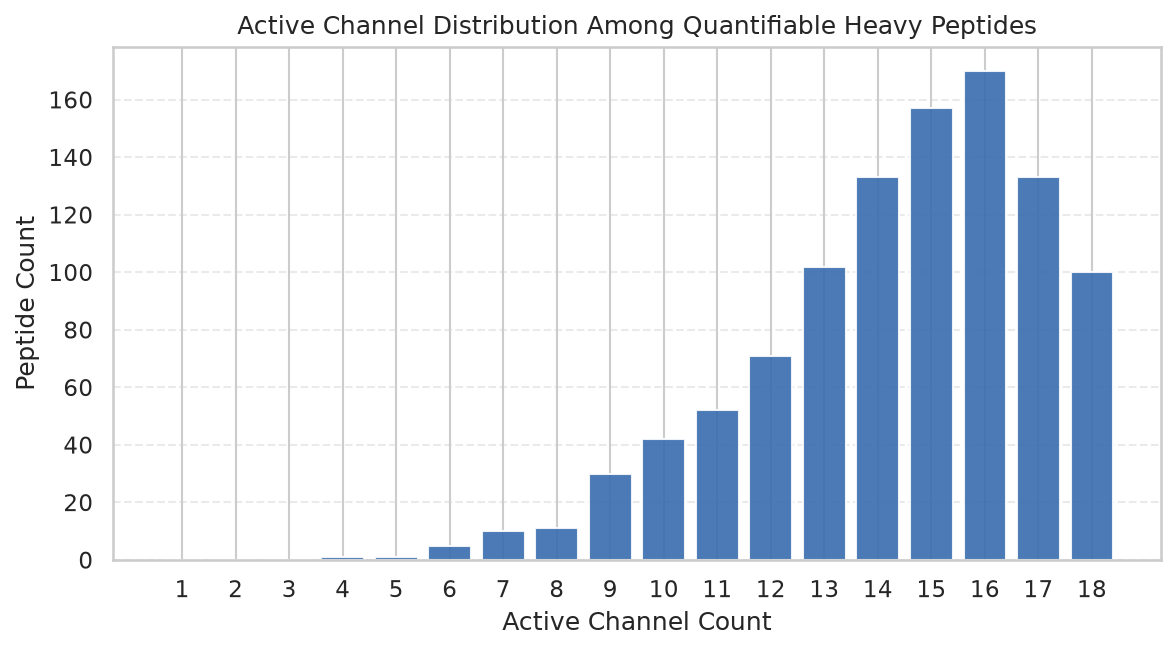

In [8]:
heavy_df = df[df["Label"] == "heavy"].copy()
mask_active = heavy_df["active_channels"] > 0

fig, ax = plt.subplots(figsize=(8, 4.5), dpi=150)
ax.hist(
    heavy_df.loc[mask_active, "active_channels"],
    bins=range(1, 20),
    align="left",
    rwidth=0.8,
    color="#386cb0",
    alpha=0.9,
)
ax.set_title("Active Channel Distribution Among Quantifiable Heavy Peptides")
ax.set_xlabel("Active Channel Count")
ax.set_ylabel("Peptide Count")
ax.set_xticks(range(1, 19))
ax.grid(axis="y", linestyle="--", alpha=0.4)
plt.tight_layout()
plt.show()

### Verification of Carrier-Only and Reference-Only Peptide Signals

To address the concern regarding potential quantification artifacts stemming from EV boost/carrier channels (Channels 126 and 127N) or synthetic spike-in reference mixtures (Channels 133N–134C), we assessed peptide occupancy across all 18 TMT channels. 

Specifically, we evaluated whether any of the 1,018 quantifiable heavy peptides were detected exclusively within carrier or reference standards while exhibiting zero signal in biological co-culture conditions (target SAOS2 cells incubated with PC3 or PC3M EVs; Channels 130N–132C, 135N).

As demonstrated below, exactly 7 peptides out of 1,018 (0.7%) were confined to carrier/reference channels and showed complete absence of signal across all 7 uptake replicates. Consequently, 1,011 heavy peptides (99.3%) possess verifiable quantification within recipient target cells, confirming that downstream uptake analysis is not distorted by carrier-only identifications.

In [9]:
# Define column lists
boost_cols = ["Abundance F13 126 Sample", "Abundance F13 127N Sample"]
spike_cols = [
    "Abundance F13 133N Sample",
    "Abundance F13 133C Sample",
    "Abundance F13 134N Sample",
    "Abundance F13 134C Sample",
]
uptake_cols = [
    "Abundance F13 130N Sample",
    "Abundance F13 130C Sample",
    "Abundance F13 131N Sample",
    "Abundance F13 131C Sample",
    "Abundance F13 132N Sample",
    "Abundance F13 132C Sample",
    "Abundance F13 135N Sample",
]

# Extract quantifiable heavy peptides
quant_heavy = heavy_df[heavy_df["active_channels"] > 0].copy()

# Check for presence of signal (non-zero values)
has_boost_only = (quant_heavy[boost_cols] > 0).any(axis=1) & (
    quant_heavy[uptake_cols] == 0
).all(axis=1)
has_spike_only = (quant_heavy[spike_cols] > 0).any(axis=1) & (
    quant_heavy[uptake_cols] == 0
).all(axis=1)
has_boost_or_spike_only = (quant_heavy[boost_cols + spike_cols] > 0).any(axis=1) & (
    quant_heavy[uptake_cols] == 0
).all(axis=1)

print(f"Peptides strictly in boost (0 in uptake): {has_boost_only.sum()}")
print(f"Peptides strictly in spikes (0 in uptake): {has_spike_only.sum()}")
print(
    f"Peptides only in boost and/or spikes (0 in uptake): {has_boost_or_spike_only.sum()}"
)

Peptides strictly in boost (0 in uptake): 7
Peptides strictly in spikes (0 in uptake): 7
Peptides only in boost and/or spikes (0 in uptake): 7


Deletion of those peptides

In [10]:
# Create a mask for peptides detected in at least one uptake channel
mask_has_uptake = (quant_heavy[uptake_cols] > 0).any(axis=1)

# Output these peptides along with their proteins and sequences for the report/appendix
excluded_peptides = quant_heavy[~mask_has_uptake][
    ["Annotated Sequence", "Master Protein Accessions", "active_channels"]
]
print(f"=== EXCLUDED PEPTIDES (n={len(excluded_peptides)}) ===")
print(excluded_peptides.to_string())

# Clean the cohort: keep exactly 1011 peptides
heavy_df = quant_heavy[mask_has_uptake].copy()
print(f"\nCleaned cohort size for protein-level rollup: {len(heavy_df)} peptides")

=== EXCLUDED PEPTIDES (n=7) ===
            Annotated Sequence Master Protein Accessions  active_channels
23923          GVLLEIEDLQVNQFK                    P46940                8
43522                NNQITNNQR                    P00558                6
50330  TATESFASDPILYRPVAVALDTK                    P14618               10
50649                GFTIPEAFR                    O00299                6
62419                  NFDEILR                    P30041                6
72645                 QASEGPLK                    P04406                6
86881                  AASGALR                    O60716                6

Cleaned cohort size for protein-level rollup: 1011 peptides


## 7. Experimental Design Mapping and Channel Annotation

We load experimental layout metadata from `TMT_pool.xlsx` and map the raw TMT reporter channels (`Abundance F13 ...`) to biological conditions.

Channels `127C` and `128N` were blank wells (negative controls). The remaining channels correspond to biological conditions:
- **SAOS-2 alone (Controls R1–R3)**: `128C`, `129N`, `129C` (baseline cellular background).
- **SAOS-2 + PC3 EV (Samples R1–R3)**: `130N`, `130C`, `131N` (non-metastatic cargo uptake).
- **SAOS-2 + PC3M EV (Samples R1–R4)**: `131C`, `132N`, `132C`, `135N` (metastatic cargo uptake).
- **Spike-in EV Cargo (Controls)**: `133N`, `133C` (PC3 spike), `134N`, `134C` (PC3M spike).

In [11]:
rename_channels = {
    "Abundance F13 126 Sample": "boost_PC3_EV",
    "Abundance F13 127N Sample": "boost_PC3M_EV",
    "Abundance F13 127C Sample": "empty_1",
    "Abundance F13 128N Sample": "empty_2",
    "Abundance F13 128C Sample": "SAOS2_ctrl_R1",
    "Abundance F13 129N Sample": "SAOS2_ctrl_R2",
    "Abundance F13 129C Sample": "SAOS2_ctrl_R3",
    "Abundance F13 130N Sample": "PC3_EV_R1",
    "Abundance F13 130C Sample": "PC3_EV_R2",
    "Abundance F13 131N Sample": "PC3_EV_R3",
    "Abundance F13 131C Sample": "PC3M_EV_R1",
    "Abundance F13 132N Sample": "PC3M_EV_R2",
    "Abundance F13 132C Sample": "PC3M_EV_R3",
    "Abundance F13 133N Sample": "spike_PC3_R1",
    "Abundance F13 133C Sample": "spike_PC3_R2",
    "Abundance F13 134N Sample": "spike_PC3M_R1",
    "Abundance F13 134C Sample": "spike_PC3M_R2",
    "Abundance F13 135N Sample": "PC3M_EV_R4",
}

meta_cols = [
    "Annotated Sequence",
    "Master Protein Accessions",
    "Positions in Master Proteins",
    "Number of Proteins",
    "Number of Protein Groups",
    "Number of PSMs",
    "q-Value",
    "Label",
    "Peptide Length",
    "active_channels",
]

df_renamed = heavy_df.rename(columns=rename_channels)
df_peptides_clean = df_renamed[
    (df_renamed["Label"] == "heavy") & (df_renamed["active_channels"] > 0)
][meta_cols + list(rename_channels.values())].copy()

print(
    f"Cleaned target peptide matrix: {df_peptides_clean.shape[0]} peptides, {df_peptides_clean.shape[1]} columns"
)
df_peptides_clean.head(3)

Cleaned target peptide matrix: 1011 peptides, 28 columns


,Annotated Sequence,Master Protein Accessions,Positions in Master Proteins,Number of Proteins,Number of Protein Groups,Number of PSMs,q-Value,Label,Peptide Length,active_channels,...,PC3_EV_R2,PC3_EV_R3,PC3M_EV_R1,PC3M_EV_R2,PC3M_EV_R3,spike_PC3_R1,spike_PC3_R2,spike_PC3M_R1,spike_PC3M_R2,PC3M_EV_R4
318,NNTVTPGGKPNK,P18077,P18077 [55-66],1,1,1,0.000038,heavy,12,15,...,5.2,4.8,5.8,8.4,9.2,103.1,71.8,87.7,99.7,4.4
415,GPPASSPAPAPK,Q15942,Q15942 [254-265],1,1,1,0.000038,heavy,12,17,...,7.8,8.0,5.8,8.5,11.3,37.5,39.1,49.7,44.2,8.1
638,GDVTAEEAAGASPAK,P49006,P49006 [11-25],1,1,1,0.000038,heavy,15,14,...,6.7,9.3,0.0,10.0,10.5,123.8,119.8,70.6,70.8,6.7


In [12]:
def map_uniprot_to_genes_chunked(
    accessions: list[str], chunk_size: int = 100
) -> dict[str, str]:
    cleaned_accs = set()
    for acc in accessions:
        if pd.notna(acc):
            first_acc = str(acc).split(";")[0].strip()
            if first_acc and not first_acc.isdigit():  # отсекаем числовые индексы
                cleaned_accs.add(first_acc)

    acc_list = list(cleaned_accs)
    mapping = {}

    url = "https://rest.uniprot.org/uniprotkb/accessions"

    # Запрашиваем батчами
    for i in range(0, len(acc_list), chunk_size):
        chunk = acc_list[i : i + chunk_size]
        params = {
            "accessions": ",".join(chunk),
            "format": "tsv",
            "fields": "accession,gene_primary",
        }
        try:
            response = requests.get(url, params=params)
            response.raise_for_status()

            df_map = pd.read_csv(io.StringIO(response.text), sep="\t")
            if not df_map.empty and "Entry" in df_map.columns:
                gene_col = (
                    "Gene Names (primary)"
                    if "Gene Names (primary)" in df_map.columns
                    else df_map.columns[1]
                )
                df_map[gene_col] = (
                    df_map[gene_col].astype(str).str.split(";").str[0].str.strip()
                )
                chunk_dict = dict(zip(df_map["Entry"], df_map[gene_col]))
                mapping.update(chunk_dict)
        except Exception as e:
            print(f"Warning: chunk {i} failed: {e}")

    return mapping

In [13]:
# Extracting the list of proteins
accession_list = (
    df_peptides_clean["Master Protein Accessions"]
    .dropna()
    .astype(str)
    .apply(lambda x: x.split(";")[0].strip())
    .tolist()
)

# Obtaining the mapping
gene_mapping = map_uniprot_to_genes_chunked(accession_list)

# Create a normalized Accession column (primary ID)
df_peptides_clean["Primary_Accession"] = (
    df_peptides_clean["Master Protein Accessions"]
    .astype(str)
    .apply(lambda x: x.split(";")[0].strip())
)

# Create a 'Genes' column: map the gene, or if it is not present in the response, keep the 'Accession' value.
df_peptides_clean["Genes"] = (
    df_peptides_clean["Primary_Accession"]
    .map(gene_mapping)
    .fillna(df_peptides_clean["Primary_Accession"])
)

# Set 'Genes' as the index
# df_peptides_clean = df_peptides_clean.set_index("Genes")

# Result
print(df_peptides_clean[["Primary_Accession", "Genes"]].head())

    Primary_Accession     Genes
318            P18077    RPL35A
415            Q15942       ZYX
638            P49006  MARCKSL1
771            P30101     PDIA3
853            P02751       FN1


In [14]:
df_peptides_clean["Genes"]

318        RPL35A
415           ZYX
638      MARCKSL1
771         PDIA3
853           FN1
           ...   
87455       TRA2B
87540      MAP4K2
87565       KPNB1
87593         VIM
87979         CNP
Name: Genes, Length: 1011, dtype: str

## 8. Protein Group Resolution and Shared Peptide Evaluation

All 1,011 peptides belong to a single protein group (`Number of Protein Groups == 1`). However, several peptides map to multiple closely related proteins within the group (`Number of Proteins > 1`).

Strict exclusion of these shared peptides would completely discard 20 proteins. Therefore, we track both cohorts:
- **`df_proteins_strict`**: Derived exclusively from strictly unique peptides.
- **`df_proteins_expanded`**: Derived from all peptides.

In [15]:
df_peptides_clean["Number of Protein Groups"].unique()

array([1])

In [16]:
unique_prot_set = set(
    df_peptides_clean[df_peptides_clean["Number of Proteins"] == 1]["Genes"]
)
shared_prot_set = set(
    df_peptides_clean[df_peptides_clean["Number of Proteins"] != 1]["Genes"]
)
lost_proteins = shared_prot_set - unique_prot_set

print(f"Proteins identified by strictly unique peptides: {len(unique_prot_set)}")
print(f"Proteins identified exclusively via shared peptides: {len(lost_proteins)}")
# if lost_proteins:
#     print("Excluded proteins:")
#     print('\n'.join(lost_proteins))

Proteins identified by strictly unique peptides: 372
Proteins identified exclusively via shared peptides: 20


In [17]:
df_shared_73 = df_peptides_clean[df_peptides_clean["Number of Proteins"] != 1]

In [18]:
df_shared_73["Genes"].unique()

<StringArray>
[    'ACTB',   'EEF1A1',   'ATP1A1',    'RPS27',   'TUBA4A',    'RPLP0',
    'ANXA2',   'NPEPPS',    'DDX3X',   'H2BC26',   'HNRNPC',  'ALDH1A3',
    'PSMA7',     'PPIA',   'H2AC11',     'H3-7',    'CLDN4', 'HSP90AB1',
     'GNAS',     'NME2',   'HSPA1B',    'H3-3A',    'EIF5A',  'HSP90B1',
 'HSP90AA1',    'PGAM1',      'PKM',    'CKAP4',     'RPL3',    'ACTC1',
  'ATP5MC3',   'RPL13A',    'HSPA5',    'RPS4X',     'TOP1',     'CAV1',
    'H2AC4',      'VIM']
Length: 38, dtype: str

In [19]:
df_shared_73[
    ["Genes", "Annotated Sequence", "Peptide Length", "Number of Proteins"]
].sort_values(by=["Genes"])

,Genes,Annotated Sequence,Peptide Length,Number of Proteins
2405,ACTB,DLYANTVLSGGTTMYPGIADR,21,2
2412,ACTB,KDLYANTVLSGGTTMYPGIADR,22,2
53219,ACTB,VAPEEHPVLLTEAPLNPK,18,2
69558,ACTC1,YPIEHGIITNWDDMEK,16,4
46760,ALDH1A3,IAFTGSTEVGK,11,2
...,...,...,...,...
14794,RPS27,LVQSPNSYFMDVK,13,2
76213,RPS4X,GIPHLVTHDAR,11,3
77176,TOP1,MLDHEYTTK,9,2
26165,TUBA4A,SIQFVDWCPTGFK,13,2


## 9. Peptide-to-Protein Abundance Aggregation

Peptide reporter intensities are aggregated to master proteins by summing raw channel values across unique peptide matches.

In [20]:
channels = [
    "boost_PC3_EV",
    "boost_PC3M_EV",
    "empty_1",
    "empty_2",
    "SAOS2_ctrl_R1",
    "SAOS2_ctrl_R2",
    "SAOS2_ctrl_R3",
    "PC3_EV_R1",
    "PC3_EV_R2",
    "PC3_EV_R3",
    "PC3M_EV_R1",
    "PC3M_EV_R2",
    "PC3M_EV_R3",
    "PC3M_EV_R4",
    "spike_PC3_R1",
    "spike_PC3_R2",
    "spike_PC3M_R1",
    "spike_PC3M_R2",
]

strict_peptides = df_peptides_clean[df_peptides_clean["Number of Proteins"] == 1].copy()

df_proteins_strict = (
    strict_peptides.groupby(["Master Protein Accessions", "Genes"])[channels]
    .sum()
    .reset_index()
)

pep_counts_strict = (
    strict_peptides.groupby("Master Protein Accessions")["Annotated Sequence"]
    .nunique()
    .rename("unique_peptides_count")
)

df_proteins_strict = df_proteins_strict.merge(
    pep_counts_strict, on="Master Protein Accessions"
)

# # Expanded dataset aggregation
# df_proteins_expanded = df_peptides_clean.groupby("Master Protein Accessions")[channels].sum().reset_index()
# pep_counts_exp = df_peptides_clean.groupby("Master Protein Accessions")["Annotated Sequence"].nunique().rename("unique_peptides_count")
# df_proteins_expanded = df_proteins_expanded.merge(pep_counts_exp, on="Master Protein Accessions")

print(f"Aggregated strict matrix:   {df_proteins_strict.shape[0]} proteins")
# print(f"Aggregated expanded matrix: {df_proteins_expanded.shape[0]} proteins")

Aggregated strict matrix:   372 proteins


### Sample-Level Quality Control

**Objective:**
To verify the technical integrity and consistency of sample preparation across all experimental channels (for the `PC3_EV` and `PC3M_EV` groups) and to identify potential systematic artifacts—such as insufficient TMT reporter addition, or issues with sample spraying or injection—prior to differential analysis.

**Metrics Evaluated:**
1. **`Total_Intensity` (Total reporter intensity):** Reflects the overall signal yield for a given channel. A sharp drop in the total intensity indicates sample loss during preparation or incomplete chemical labeling ("underlabeling").
2. **`Median_Intensity`:** Represents the central tendency of the signal distribution. This value should be well above the level of instrument noise ($6.5–7.0$).
3. **`Quantified_Proteins` and `Zero_Count`:** The number of proteins with a detectable signal ($> 0$) versus the number of zero-value entries. An abnormal increase in the proportion of zeros suggests that the signal has fallen below the instrument's limit of detection (LOD).

**Assessment Criterion:**
A channel is classified as a "technical outlier" if its integral characteristics show a significant deviation (by a factor of several-fold) from those of the corresponding biological replicates within the same experimental group.

In [21]:
cols_to_check = [
    "PC3_EV_R1",
    "PC3_EV_R2",
    "PC3_EV_R3",
    "PC3M_EV_R1",
    "PC3M_EV_R2",
    "PC3M_EV_R3",
    "PC3M_EV_R4",
]

qc_summary = pd.DataFrame(
    {
        "Total_Intensity": df_proteins_strict[cols_to_check].sum(),
        "Median_Intensity": df_proteins_strict[cols_to_check].median(),
        "Quantified_Proteins": (df_proteins_strict[cols_to_check] > 0).sum(),
        "Zero_Count": (df_proteins_strict[cols_to_check] == 0).sum(),
    }
)

print(qc_summary)

            Total_Intensity  Median_Intensity  Quantified_Proteins  Zero_Count
PC3_EV_R1            2266.9              2.90                  249         123
PC3_EV_R2            7448.2              9.00                  346          26
PC3_EV_R3            8614.1             10.70                  351          21
PC3M_EV_R1           7073.7             10.60                  343          29
PC3M_EV_R2           9511.2             13.15                  364           8
PC3M_EV_R3          10844.9             15.25                  370           2
PC3M_EV_R4           7100.4             10.55                  357          15


**Quality Control Assessment and Handling of `PC3_EV_R1`:**  
Replicates `PC3_EV_R2` and `PC3_EV_R3` exhibited strong pairwise concordance (Spearman $r = 0.955$). In contrast, replicate `PC3_EV_R1` demonstrated severe analytical suppression:
- Total reporter ion intensity was suppressed >3.5-fold relative to parallel replicates ($2266.9$ vs. $7448.2$ and $8614.1$).
- Channel-wide median intensity dropped to baseline instrument noise ($2.90$).
- Protein dropout reached $33.1\%$ ($123/372$ zero-intensity values), driving low correlation ($r = 0.58\text{--}0.62$) and marked separation along principal components.

Rather than reflecting authentic biological heterogeneity, these diagnostic metrics indicate a systemic pre-analytical/labeling failure (severe underlabeling causing reporter intensities to fall below the instrument limit of detection). Retaining this channel would introduce substantial dilution bias into the PC3 group, whereas imputing missing values against highly correlated duplicates ($r = 0.955$) would artificially deflate analytical variance. 

Consequently, based on objective quality control criteria, `PC3_EV_R1` was formally classified as an analytical outlier and excluded from downstream quantitative evaluations. 

In [22]:
df_proteins_strict.drop(columns=["PC3_EV_R1"], inplace=True)
channels = [
    "boost_PC3_EV",
    "boost_PC3M_EV",
    "empty_1",
    "empty_2",
    "SAOS2_ctrl_R1",
    "SAOS2_ctrl_R2",
    "SAOS2_ctrl_R3",
    "PC3_EV_R2",
    "PC3_EV_R3",
    "PC3M_EV_R1",
    "PC3M_EV_R2",
    "PC3M_EV_R3",
    "PC3M_EV_R4",
    "spike_PC3_R1",
    "spike_PC3_R2",
    "spike_PC3M_R1",
    "spike_PC3M_R2",
]

## 10. Background Noise Filtering Against Recipient Cell Controls

To remove non-specific background noise originating from recipient cells from the pool of extracellular vesicle (EV) cargo proteins, a two-parameter filter is applied:
1. **Absolute signal threshold ($\alpha$):** $\max(\text{Median}_{\text{PC3}}, \text{Median}_{\text{PC3M}}) > \alpha$
2. **Fold-change over background ($\beta$):** $\max(\text{Median}_{\text{PC3}}, \text{Median}_{\text{PC3M}}) \ge \beta \times \text{Median}_{\text{SAOS2 ctrl}}$

The parameters $\alpha$ and $\beta$ are determined empirically based on an analysis of the distributions of negative controls (`SAOS-2 alone`) and empty channels (`empty`), as well as an assessment of the technical variability of the measurements.

### Step 1. Assessment of the instrumental background level and selection of $\alpha$


**Objective:** To determine the physical detection noise level and the instrumental background (reporter ion leakage / chemical noise).


**Expectation:** In control and empty channels, the values ​​fall within the range of instrumental noise. The median of this distribution is taken as the baseline threshold, $\alpha$, which filters out random, low-intensity fluctuations.

In [23]:
# negative biological control channels and blank instrumental controls
saos_ctrl_channels = ["SAOS2_ctrl_R1", "SAOS2_ctrl_R2", "SAOS2_ctrl_R3"]
empty_channels = ["empty_1", "empty_2"]

# extract non-zero values ​​(values ​​> 0 filter out the hardware-based LOD cutoff)
saos_vals = df_proteins_strict[saos_ctrl_channels].values.flatten()
saos_vals = saos_vals[(~np.isnan(saos_vals)) & (saos_vals > 0)]

empty_vals = df_proteins_strict[empty_channels].values.flatten()
empty_vals = empty_vals[(~np.isnan(empty_vals)) & (empty_vals > 0)]

# calculate background noise percentiles
quantiles = [0.25, 0.50, 0.75, 0.90, 0.95]
noise_summary = pd.DataFrame(
    {
        "SAOS2_ctrl": np.quantile(saos_vals, quantiles),
        "Empty_channels": np.quantile(empty_vals, quantiles),
    },
    index=[f"q{int(q * 100)}" for q in quantiles],
)

print("--- Quantiles of the background distribution ---")
print(noise_summary.round(2))

# setting the alpha threshold to the median of the background
alpha_threshold = np.round(np.median(saos_vals), 1)
print(f"\nSelected alpha threshold (median of SAOS-2): {alpha_threshold}")

--- Quantiles of the background distribution ---
     SAOS2_ctrl  Empty_channels
q25        3.70            3.70
q50        6.55            7.00
q75       12.90           14.90
q90       25.80           31.93
q95       37.00           45.65

Selected alpha threshold (median of SAOS-2): 6.6


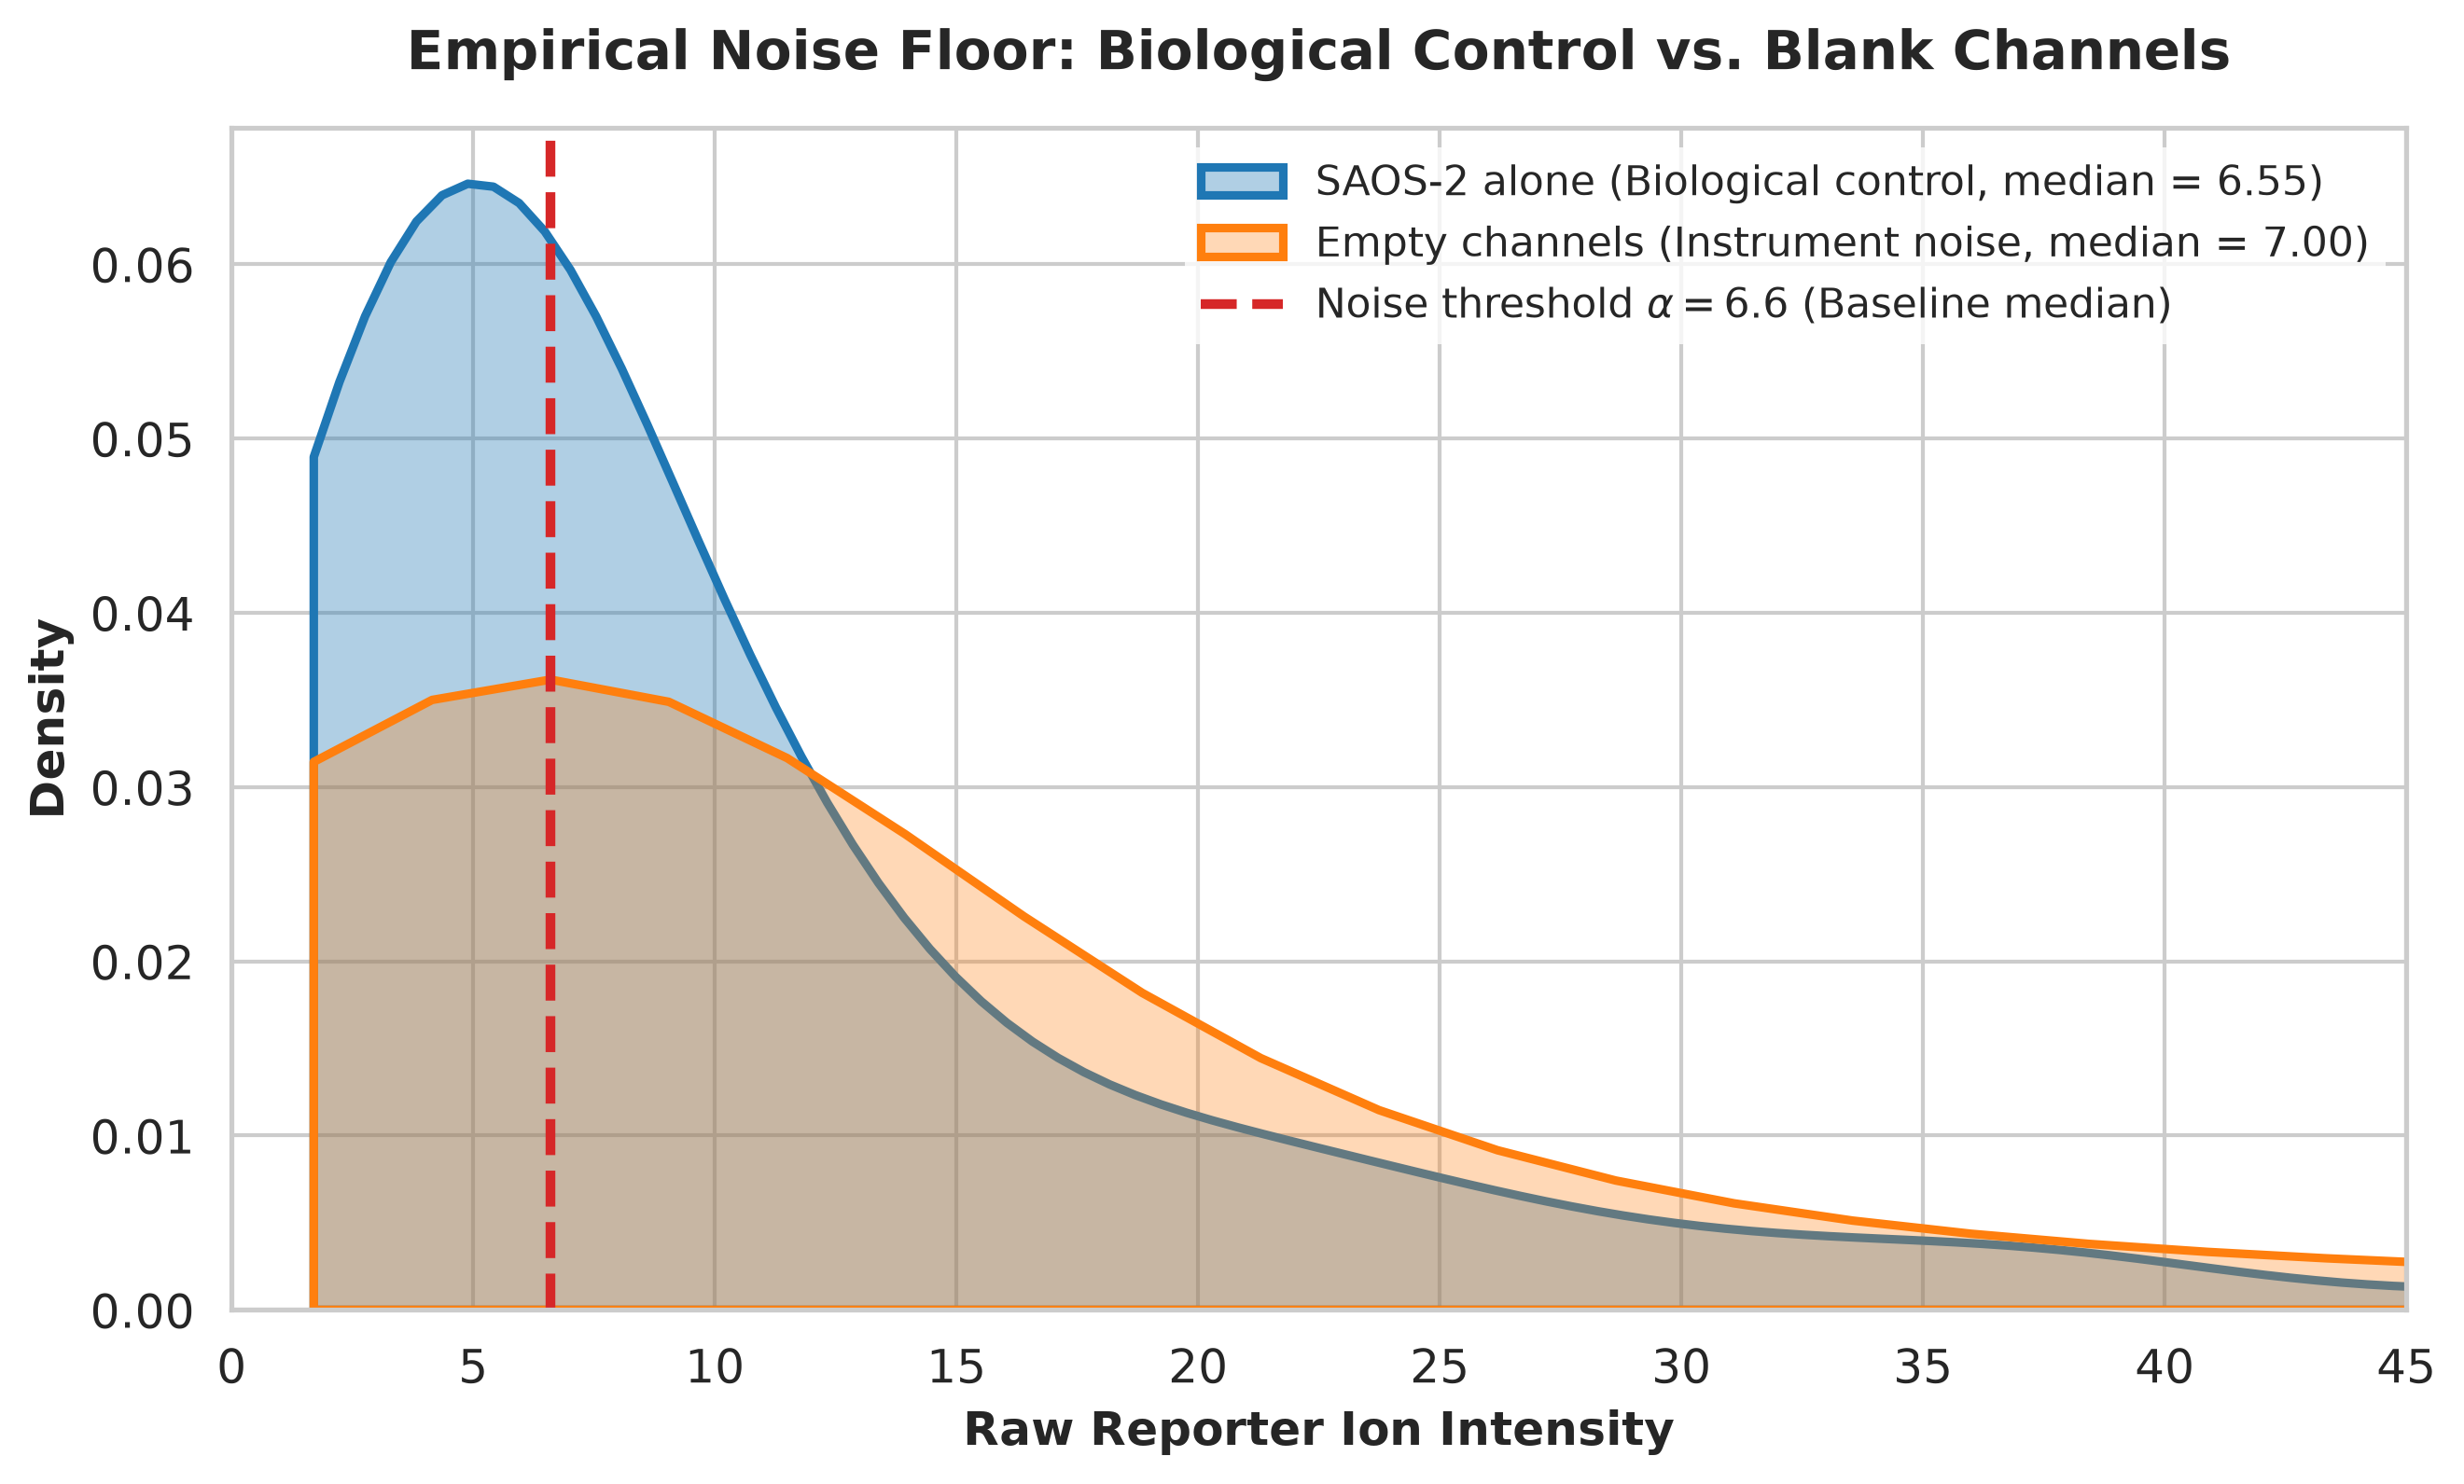

In [24]:
saos_ctrl_channels = ["SAOS2_ctrl_R1", "SAOS2_ctrl_R2", "SAOS2_ctrl_R3"]
empty_channels = ["empty_1", "empty_2"]

saos_vals = df_proteins_strict[saos_ctrl_channels].values.flatten()
saos_vals = saos_vals[(~np.isnan(saos_vals)) & (saos_vals > 0)]

empty_vals = df_proteins_strict[empty_channels].values.flatten()
empty_vals = empty_vals[(~np.isnan(empty_vals)) & (empty_vals > 0)]

saos_med = np.median(saos_vals)
empty_med = np.median(empty_vals)
alpha_threshold = 6.6  # или np.round(saos_med, 1)

plt.figure(figsize=(9, 5.5), dpi=300)
sns.set_theme(style="whitegrid", font_scale=1.1)

sns.kdeplot(
    saos_vals,
    label=f"SAOS-2 alone (Biological control, median = {saos_med:.2f})",
    color="#1f77b4",
    fill=True,
    alpha=0.35,
    linewidth=2.2,
    cut=0,
)

sns.kdeplot(
    empty_vals,
    label=f"Empty channels (Instrument noise, median = {empty_med:.2f})",
    color="#ff7f0e",
    fill=True,
    alpha=0.30,
    linewidth=2.2,
    cut=0,
)

plt.axvline(
    x=alpha_threshold,
    color="#d62728",
    linestyle="--",
    linewidth=2.5,
    label=rf"Noise threshold $\alpha = {alpha_threshold}$ (Baseline median)",
)

plt.xlim(0, 45) 
plt.xlabel("Raw Reporter Ion Intensity", fontsize=12, fontweight="bold")
plt.ylabel("Density", fontsize=12, fontweight="bold")
plt.title(
    "Empirical Noise Floor: Biological Control vs. Blank Channels",
    fontsize=14,
    fontweight="bold",
    pad=15,
)

plt.legend(frameon=True, facecolor="white", edgecolor="none", fontsize=10.5)
plt.tight_layout()

# plt.savefig("noise_floor_distribution.png", dpi=300)
plt.show()

### Step 2. Estimation of technical variability ($CV$) and justification of $\beta$


**Objective:** To measure the coefficient of variation ($CV = SD / Mean$) among biological/technical replicates of the SAOS-2 control group.


**Expectation:** The fold-change threshold $\beta$ must be set to reliably exceed the confidence interval of the technical error observed across the replicates ($> 3 \times CV$).

In [25]:
# Assessing variability between SAOS-2 replicates
df_ctrl_reps = df_proteins_strict[saos_ctrl_channels].replace(0, np.nan)

# Calculate the CV for each protein that shows a signal in the control group
cv_series = df_ctrl_reps.std(axis=1) / df_ctrl_reps.mean(axis=1)
median_cv = cv_series.median()

print(f"Median CV for negative control replicates: {median_cv:.2%}")

Median CV for negative control replicates: 23.83%


With a CV of ≈ 24%, random background fluctuation falls within a range of ±48% (2*SD). The beta threshold of 2.0 (a 100% increase) exceeds this random variation by more than fourfold.

In [26]:
beta_threshold = 2.0
print(f"Selected beta threshold (fold-change relative to background): {beta_threshold}")

Selected beta threshold (fold-change relative to background): 2.0


### Step 3. Final filtering of the protein pool
**Selection criteria:**
- The protein must have a maximum median intensity across the experimental groups that is strictly higher than the median background noise ($\alpha = 6.6$).
- The signal in the experimental groups must be at least 2 times ($\beta = 2.0$) higher than the median signal level in the SAOS-2 control group.

In [27]:
# Calculating median intensities by group
pc3_cols = [c for c in df_proteins_strict.columns if c.startswith("PC3_EV_R")]
pc3m_cols = [c for c in df_proteins_strict.columns if c.startswith("PC3M_EV_R")]

median_pc3 = df_proteins_strict[pc3_cols].median(axis=1).fillna(0)
median_pc3m = df_proteins_strict[pc3m_cols].median(axis=1).fillna(0)
median_saos = df_proteins_strict[saos_ctrl_channels].median(axis=1).fillna(0)

max_sample_median = np.maximum(median_pc3, median_pc3m)

# Applying filters
pass_alpha = max_sample_median > alpha_threshold
pass_beta = max_sample_median >= (beta_threshold * median_saos)

df_strict_filtered = df_proteins_strict[pass_alpha & pass_beta].copy()

print(f"Initial number of proteins: {len(df_proteins_strict)}")
print(f"Passed alpha threshold ({alpha_threshold}): {pass_alpha.sum()}")
print(f"Passed both filters (alpha and beta): {len(df_strict_filtered)}")

Initial number of proteins: 372
Passed alpha threshold (6.6): 284
Passed both filters (alpha and beta): 212


## 11. Spike-in Normalization and Input Scaling

To account for EV input loading differences, sample intensities are normalized to the internal pure-EV spike channels. A $2\times$ NTA particle adjustment factor is applied to PC3 channels ($-1.0$ on the $\log_2$ scale):

$$\log_2(I_{\text{norm}}) = \log_2(I_{\text{sample}}) - \log_2(I_{\text{spike}}) - \text{offset}$$

Isolated dropouts at the detection limit are substituted deterministically using empirical LOD/2

But firstly, we need to check if there are any missing values or 0s: otherwise normalization cannot be computed!

In [28]:
vals = df_proteins_strict[channels].to_numpy(dtype=float).flatten()
emp_lod = np.nanmin(vals[vals > 0])

print(f"Empirical LOD: {emp_lod:.4f}")

Empirical LOD: 1.7000


In [29]:
exp_channels = [
    "PC3_EV_R2",
    "PC3_EV_R3",
    "PC3M_EV_R1",
    "PC3M_EV_R2",
    "PC3M_EV_R3",
    "PC3M_EV_R4",
]
spike_channels = [
    "spike_PC3_R1",
    "spike_PC3_R2",
    "spike_PC3M_R1",
    "spike_PC3M_R2",
]
all_target_channels = exp_channels + spike_channels

# check for zeros and NaNs in the filtered dataframe
df_check = df_strict_filtered[all_target_channels].copy()

# replace explicit zeros with NaN for accurate counting
df_check_nan = df_check.replace(0, np.nan)

# count the number of zeros / missing values ​​for each channel separately
zeros_per_channel = (df_check == 0).sum()
nan_per_channel = df_check.isna().sum()

summary_channels = pd.DataFrame(
    {
        "Zero_Count": zeros_per_channel,
        "NaN_Count": nan_per_channel,
        "Total_Missing": (df_check == 0).sum() + df_check.isna().sum(),
    }
)

print("=== Missing values and zeros by channel ===")
print(summary_channels)

# calculate the distribution of missing values ​​by protein (for the 6 experimental channels only)
exp_zeros_per_protein = (df_check[exp_channels] == 0).sum(axis=1) + df_check[
    exp_channels
].isna().sum(axis=1)

print(
    "\n=== Distribution of missing values across proteins (among 6 experimental channels) ==="
)
print(exp_zeros_per_protein.value_counts().sort_index())

complete_cases_count = (exp_zeros_per_protein == 0).sum()
print(
    f"\nProteins with no missing values (zeros) across all 6 channels: {complete_cases_count} out of"
    f" {len(df_strict_filtered)}"
)

=== Missing values and zeros by channel ===
               Zero_Count  NaN_Count  Total_Missing
PC3_EV_R2               1          0              1
PC3_EV_R3               0          0              0
PC3M_EV_R1              1          0              1
PC3M_EV_R2              0          0              0
PC3M_EV_R3              0          0              0
PC3M_EV_R4              0          0              0
spike_PC3_R1            0          0              0
spike_PC3_R2            0          0              0
spike_PC3M_R1           0          0              0
spike_PC3M_R2           0          0              0

=== Distribution of missing values across proteins (among 6 experimental channels) ===
0    210
1      2
Name: count, dtype: int64

Proteins with no missing values (zeros) across all 6 channels: 210 out of 212


Its just 2 of them, lets look closer 

In [30]:
# Identify rows containing zeros across the 6 experimental channels
mask_missing = (df_check[exp_channels] == 0).any(axis=1)
df_two_proteins = df_strict_filtered[mask_missing].copy()

# Display identifiers and intensities
display_cols = [
    c
    for c in ["Master Protein Accessions", "Genes"]
    if c in df_two_proteins.columns
]
display_cols += exp_channels

print("Two proteins with isolated missing values:")
display(df_two_proteins[display_cols])

Two proteins with isolated missing values:


,Master Protein Accessions,Genes,PC3_EV_R2,PC3_EV_R3,PC3M_EV_R1,PC3M_EV_R2,PC3M_EV_R3,PC3M_EV_R4
143,P29279,CCN2,11.8,11.6,0.0,5.2,7.5,3.1
247,P62917,RPL8,0.0,4.1,12.9,9.6,13.4,8.7


**Data Completeness and Boundary-Level LOD Handling:**  
Across the authenticated 6-channel framework ($n = 2$ for PC3-EV, $n = 4$ for PC3M-EV):
- 210 out of 212 proteins ($99.05\%$) exhibited complete quantification across all channels with zero missing values.
- For the remaining two proteins (CTGF/P29279 and RPL8/P62917, representing $0.15\%$ of total data points), single stochastic dropouts near the boundary of detection were handled by deterministic substitution at the empirical limit of detection ($\text{LOD} \approx 1.7$; substituted as $\text{LOD}/{2} \approx 0.85$). 

This conservative approach prevents synthetic variance distortion while preserving full dataset dimensionality ($N = 212$) for downstream multivariate PCA and differential uptake analysis.

In [31]:
df_imputed = df_strict_filtered.copy()
df_imputed[exp_channels] = df_imputed[exp_channels].replace(0, emp_lod / 2)

remaining_zeros = (df_imputed[exp_channels] == 0).sum().sum()
print(f"Remaining zeros in the 6 channels: {remaining_zeros}")
print(f"Final size of the unified protein cohort: N = {len(df_imputed)}")

Remaining zeros in the 6 channels: 0
Final size of the unified protein cohort: N = 212


Perform normalization

In [32]:
def normalize_uptake_212(df_in):
    df_clean = df_in.copy()

    # Calculation of the log-transformed spike-in (geometric mean of replicates)
    spike_pc3_raw = df_clean[["spike_PC3_R1", "spike_PC3_R2"]].astype(float)
    spike_pc3m_raw = df_clean[["spike_PC3M_R1", "spike_PC3M_R2"]].astype(float)

    log_spike_pc3 = np.log2(spike_pc3_raw).mean(axis=1).values
    log_spike_pc3m = np.log2(spike_pc3m_raw).mean(axis=1).values

    df_log2_norm = pd.DataFrame(index=df_clean["Master Protein Accessions"])

    # PC3 (R2, R3) with NTA 2x adjustment (-1.0 on a log2 scale)
    for col in ["PC3_EV_R2", "PC3_EV_R3"]:
        vals = df_clean[col].astype(float).values
        df_log2_norm[f"norm_{col}"] = np.log2(vals) - log_spike_pc3 - 1.0

    # PC3M (R1, R2, R3, R4)
    for col in ["PC3M_EV_R1", "PC3M_EV_R2", "PC3M_EV_R3", "PC3M_EV_R4"]:
        vals = df_clean[col].astype(float).values
        df_log2_norm[f"norm_{col}"] = np.log2(vals) - log_spike_pc3m

    return df_log2_norm

## 12. Exploratory PCA and Quality-Driven Replicate Evaluation Policy

Principal Component Analysis (PCA) and pairwise correlation metrics were evaluated across the validated EV cargo cohort ($N = 212$).


findfont: Failed to find font weight semibold for DejaVu Sans, now using 700.


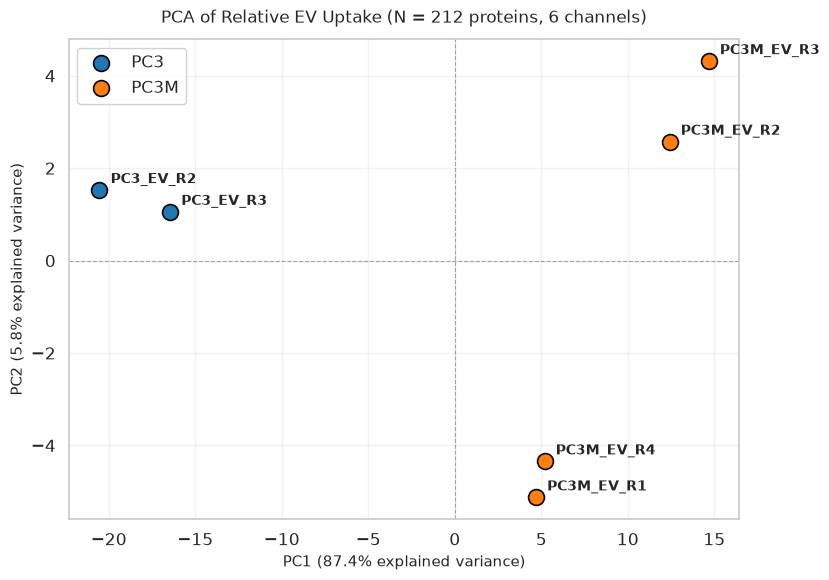

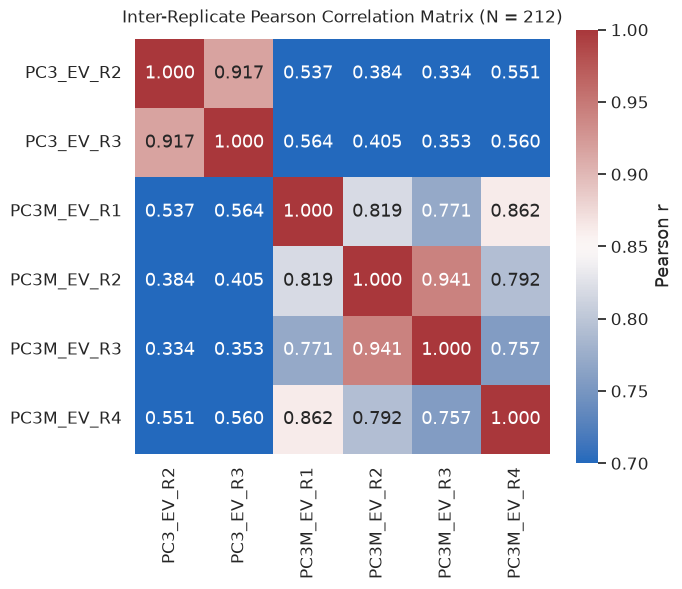

In [33]:
df_norm_212 = normalize_uptake_212(df_imputed)

X = df_norm_212.T
sample_names = X.index.tolist()
labels = ["PC3" if "PC3_EV" in s and "PC3M" not in s else "PC3M" for s in sample_names]
colors = {"PC3": "#1f77b4", "PC3M": "#ff7f0e"}

# Feature standardization (z-score for each protein)
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

pca = PCA(n_components=2)
coords = pca.fit_transform(X_scaled)

var_pc1 = pca.explained_variance_ratio_[0] * 100
var_pc2 = pca.explained_variance_ratio_[1] * 100

# 4. Creating a PCA Score Plot
plt.figure(figsize=(8.5, 6))
plotted_labels = set()

for i, sample in enumerate(sample_names):
    group = labels[i]
    plot_label = group if group not in plotted_labels else ""
    plotted_labels.add(group)

    plt.scatter(
        coords[i, 0],
        coords[i, 1],
        color=colors[group],
        s=130,
        edgecolor="black",
        linewidth=1.2,
        label=plot_label,
    )
    plt.annotate(
        sample.replace("norm_", ""),
        (coords[i, 0], coords[i, 1]),
        textcoords="offset points",
        xytext=(8, 5),
        fontsize=10,
        weight="semibold",
    )

plt.axhline(0, color="grey", linestyle="--", linewidth=0.8, alpha=0.7)
plt.axvline(0, color="grey", linestyle="--", linewidth=0.8, alpha=0.7)
plt.title(
    f"PCA of Relative EV Uptake (N = {len(df_norm_212)} proteins, 6 channels)",
    fontsize=12,
    pad=12,
)
plt.xlabel(f"PC1 ({var_pc1:.1f}% explained variance)", fontsize=11)
plt.ylabel(f"PC2 ({var_pc2:.1f}% explained variance)", fontsize=11)
plt.legend(frameon=True, facecolor="white", framealpha=0.9, loc="best")
plt.grid(alpha=0.25)
plt.tight_layout()
plt.show()

# 5. Pearson correlation matrix between 6 replicates
plt.figure(figsize=(7, 6))
clean_labels = [c.replace("norm_", "") for c in df_norm_212.columns]
corr_matrix = df_norm_212.corr(method="pearson")
corr_matrix.columns = clean_labels
corr_matrix.index = clean_labels

sns.heatmap(
    corr_matrix,
    annot=True,
    fmt=".3f",
    cmap="vlag",
    vmin=0.70,
    vmax=1.0,
    cbar_kws={"label": "Pearson r"},
    square=True,
)
plt.title(
    f"Inter-Replicate Pearson Correlation Matrix (N = {len(df_norm_212)})",
    fontsize=12,
    pad=12,
)
plt.tight_layout()
plt.show()

## 13. Identification of the Global Scale Effect (PC1 Bulk Uptake Bias)

Examination of the feature eigenvectors (loadings) for the first principal component (PC1) reveals a directional shift across the cargo proteome: 211 out of 212 evaluated proteins ($99.5\%$) exhibit strictly positive loading coefficients (ranging up to $+0.0734$). Only a single protein displays a negative PC1 projection ($-0.0628$).

Leading principal component (87.4% explained variance) dominated by unidirectional feature loadings reflects a  **global scale effect**. This demonstrates that the primary axis of variance does not represent reciprocal or balanced pathway reprogramming between conditions. Instead, it captures a coordinated global phenomenon, where recipient SAOS-2 osteoblasts internalize metastatic PC3M-derived extracellular vesicle cargo at a systematically higher absolute rate/volume than cargo derived from non-metastatic PC3 cells.

In [34]:
loadings_pc1 = pca.components_[0]
print(f"PC1 Loadings: min = {loadings_pc1.min():+.4f}, max = {loadings_pc1.max():+.4f}")
print(
    f"Proportion of positive loadings: {(loadings_pc1 > 0).sum()} / {len(loadings_pc1)}"
)

PC1 Loadings: min = -0.0628, max = +0.0734
Proportion of positive loadings: 211 / 212


## 14. Sample-Median Centering: Isolating Relative Cargo Selectivity

Because PC1 in global PCA captured bulk endocytosis/internalization kinetics (where PC3M cargo is internalized at a higher volume overall), absolute differences reflect both bulk uptake and true stoichiometric composition. 

To isolate **relative cargo selectivity** (which proteins are enriched or depleted specifically within the internalized vesicle payload, independent of bulk uptake volume), we perform sample-median centering across the normalized channels:

$$\text{Signal}_{\text{rel}, ij} = \text{Signal}_{ij} - \text{Median}_j$$

Where:
- $\text{Signal}_{ij}$ is the $\log_2$-transformed normalized uptake for protein $i$ in channel $j$.
- $\text{Median}_j$ is the channel-wide median of all 212 proteins for channel $j$.

**Analytical Outcome:**
- Shifts each sample distribution to a common median ($0.0$ on $\log_2$ scale).
- Eliminates global loading/internalization asymmetry along PC1.
- Highlights proteins displaying genuine differential stoichiometry between non-metastatic (PC3) and metastatic (PC3M) cargo.

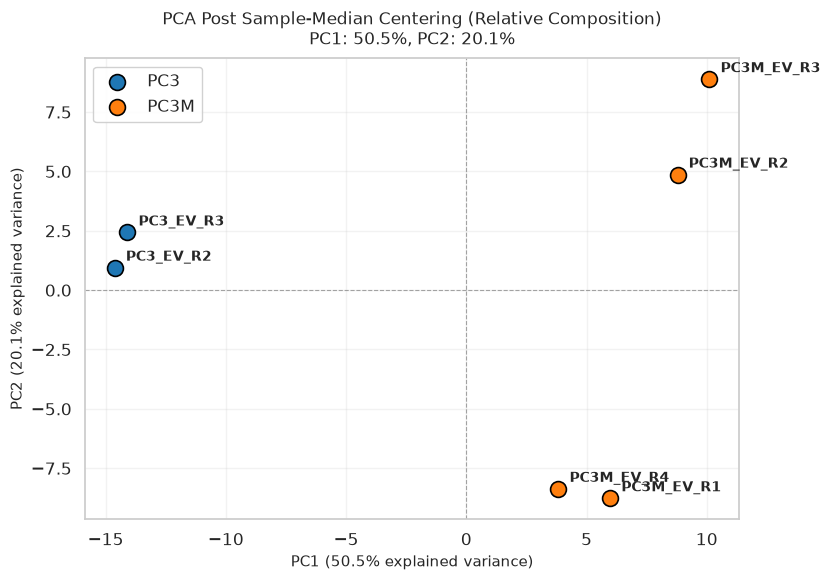

In [35]:
# Sample-median centering across all 6 channels
df_centered = df_norm_212.copy()
sample_medians = df_centered.median(axis=0)
df_centered = df_centered.sub(sample_medians, axis=1)

# PCA on centered features
X_cent = df_centered.T
scaler_cent = StandardScaler()
X_cent_scaled = scaler_cent.fit_transform(X_cent)

pca_cent = PCA(n_components=2)
coords_cent = pca_cent.fit_transform(X_cent_scaled)

var_pc1_c = pca_cent.explained_variance_ratio_[0] * 100
var_pc2_c = pca_cent.explained_variance_ratio_[1] * 100

# PCA Score Plot post-centering
plt.figure(figsize=(8.5, 6))
plotted_labels = set()

for i, sample in enumerate(sample_names):
    group = labels[i]
    plot_label = group if group not in plotted_labels else ""
    plotted_labels.add(group)

    plt.scatter(
        coords_cent[i, 0],
        coords_cent[i, 1],
        color=colors[group],
        s=130,
        edgecolor="black",
        linewidth=1.2,
        label=plot_label,
    )
    plt.annotate(
        sample.replace("norm_", ""),
        (coords_cent[i, 0], coords_cent[i, 1]),
        textcoords="offset points",
        xytext=(8, 5),
        fontsize=10,
        weight="semibold",
    )

plt.axhline(0, color="grey", linestyle="--", linewidth=0.8, alpha=0.7)
plt.axvline(0, color="grey", linestyle="--", linewidth=0.8, alpha=0.7)
plt.title(
    f"PCA Post Sample-Median Centering (Relative Composition)\nPC1: {var_pc1_c:.1f}%, PC2: {var_pc2_c:.1f}%",
    fontsize=12,
    pad=10,
)
plt.xlabel(f"PC1 ({var_pc1_c:.1f}% explained variance)", fontsize=11)
plt.ylabel(f"PC2 ({var_pc2_c:.1f}% explained variance)", fontsize=11)
plt.legend(frameon=True, facecolor="white", framealpha=0.9, loc="best")
plt.grid(alpha=0.25)
plt.tight_layout()
plt.show()

In [36]:
# Relative Delta calculation across validated replicates (PC3 n=2, PC3M n=4)
pc1_loadings_cent = pd.Series(
    pca_cent.components_[0],
    index=df_centered.index,
    name="PC1_Loading_Centered",
)

mean_rel_pc3 = df_centered[["norm_PC3_EV_R2", "norm_PC3_EV_R3"]].mean(axis=1)
mean_rel_pc3m = df_centered[
    [
        "norm_PC3M_EV_R1",
        "norm_PC3M_EV_R2",
        "norm_PC3M_EV_R3",
        "norm_PC3M_EV_R4",
    ]
].mean(axis=1)
rel_diff = (mean_rel_pc3m - mean_rel_pc3).rename("Relative_Delta_PC3M_vs_PC3")

# Merging with Genes from the original dataframe
gene_annot = df_imputed.set_index("Master Protein Accessions")["Genes"]

cent_drivers = pd.concat([gene_annot, pc1_loadings_cent, rel_diff], axis=1)
cent_drivers = cent_drivers.reset_index(drop=True)

print("\n=== Top Proteins with Relative Cargo Selectivity (PC3M enriched) ===")
print(
    cent_drivers.sort_values(by="Relative_Delta_PC3M_vs_PC3", ascending=False).head(10)
)

print("\n=== Top Proteins with Relative Cargo Selectivity (PC3 enriched) ===")
print(
    cent_drivers.sort_values(by="Relative_Delta_PC3M_vs_PC3", ascending=True).head(10)
)


=== Top Proteins with Relative Cargo Selectivity (PC3M enriched) ===
      Genes  PC1_Loading_Centered  Relative_Delta_PC3M_vs_PC3
42   COL4A2              0.095764                    6.014406
75     TGM2              0.094832                    4.126660
23      FN1              0.094745                    3.761799
78      TNC              0.091768                    2.106766
125   ITGA1              0.093116                    2.012386
13   CTNND1              0.096061                    1.973426
195    EHD1              0.054657                    1.815406
58    ANPEP              0.095653                    1.791282
4      CCN1              0.093940                    1.705974
1     CLIC1              0.079106                    1.623519

=== Top Proteins with Relative Cargo Selectivity (PC3 enriched) ===
       Genes  PC1_Loading_Centered  Relative_Delta_PC3M_vs_PC3
168  MAP3K12             -0.095923                   -2.249427
186     HM13             -0.094925                   

### It is just a function to draw a volcano plot located here to reduce the amount of code in the following cells:

In [37]:
def plot_volcano(
    volcano_df: pd.DataFrame,
    fc_threshold: float = 1.0,
    fdr_threshold: float = 0.10,
    method: str = "UNKNOWN",
    xlim: tuple[float, float] = (-3.0, 3.0),
) -> None:
    """Plot a differential expression volcano plot with FDR cutoff and significant gene labels."""
    fig, ax = plt.subplots(figsize=(9, 7))

    # Color palette mapped to status categories
    color_map = {
        "Not Significant": "#d3d3d3",
        f"Up in PC3M (FDR < {fdr_threshold:.2f})": "#ff7f0e",
        f"Up in PC3 (FDR < {fdr_threshold:.2f})": "#1f77b4",
    }

    # Render points grouped by significance status
    # Prioritize plotting non-significant points first so hits stay on top
    statuses = sorted(
        volcano_df["Significance"].unique(),
        key=lambda s: 0 if s == "Not Significant" else 1,
    )

    for status in statuses:
        subset = volcano_df[volcano_df["Significance"] == status]
        is_sig = status != "Not Significant"
        ax.scatter(
            subset["Log2FC"],
            subset["neg_log10_p"],
            c=color_map.get(status, "#7f7f7f"),
            label=status,
            alpha=0.85,
            edgecolors="black" if is_sig else "none",
            linewidth=0.6,
            s=65 if is_sig else 40,
            zorder=3 if is_sig else 2,
        )

    # Fold change thresholds
    ax.axvline(fc_threshold, color="black", linestyle="--", linewidth=0.8, alpha=0.7)
    ax.axvline(-fc_threshold, color="black", linestyle="--", linewidth=0.8, alpha=0.7)

    # Nominal p-value cutoff corresponding to the FDR threshold
    sig_hits = volcano_df[volcano_df["FDR_Significant"]]
    if not sig_hits.empty:
        p_cutoff_nominal = sig_hits["p_value"].max()
        ax.axhline(
            -np.log10(p_cutoff_nominal),
            color="red",
            linestyle="--",
            linewidth=0.9,
            label=f"FDR = {fdr_threshold:.2f} cutoff (nominal p ≈ {p_cutoff_nominal:.4f})",
        )

    # Annotate significant proteins with Genes (fallback to Accession)
    sig_proteins = volcano_df[volcano_df["Significance"] != "Not Significant"]
    for acc, row in sig_proteins.iterrows():
        label_text = str(row["Gene"]) if pd.notna(row["Gene"]) else str(acc)
        ax.annotate(
            label_text,
            xy=(row["Log2FC"], row["neg_log10_p"]),
            textcoords="offset points",
            xytext=(6, 4),
            fontsize=7,
            fontweight="bold",
        )

    # Plot aesthetics
    ax.set_title(
        f"Volcano Plot: Relative Specificity of EV Uptake (PC3M vs. PC3)\n"
        f"{method} t-test (FDR < {fdr_threshold:.2f}, |Log2FC| ≥ {fc_threshold:.1f})",
        fontsize=12,
        pad=12,
    )
    ax.set_xlabel("Relative Log2 Fold Change (PC3M vs. PC3)", fontsize=11)
    ax.set_ylabel(r"$-\log_{10}(\mathrm{nominal\ } p\mathrm{-value})$", fontsize=11)
    ax.set_xlim(xlim)
    ax.grid(alpha=0.25, linestyle="--")
    ax.legend(frameon=True, facecolor="white", framealpha=0.9, loc="upper right")

    plt.tight_layout()
    plt.show()

    # Results summary
    print(
        f"Total proteins passing FDR < {fdr_threshold:.2f} and |Log2FC| >= {fc_threshold:.1f}: "
        f"{len(sig_proteins)}\n"
    )
    display_cols = ["Gene", "Log2FC", "p_value", "q_value", "Significance"]
    print(sig_proteins[display_cols].sort_values(by="q_value").to_string())

## 15. Exploratory Differential Uptake Analysis: Welch's t-Test (Baseline Screening)

As an initial, exploratory step, we evaluate differential relative uptake between PC3 ($n_1 = 2$: `R2`, `R3`) and PC3M ($n_2 = 4$: `R1`, `R2`, `R3`, `R4`) using an unmoderated Welch's $t$-test.

### Methodological Motivation
Standard Student's $t$-test assumes equal variances across groups—an assumption regularly violated in label-free mass spectrometry due to intensity-dependent noise and uneven group sizes ($n_1 \ne n_2$). Welch's adaptation foregoes the pooled variance constraint by estimating effective degrees of freedom adaptively via the Welch–Satterthwaite approximation:

$$\nu \approx \frac{\left(\frac{s_1^2}{n_1} + \frac{s_2^2}{n_2}\right)^2}{\frac{(s_1^2 / n_1)^2}{n_1 - 1} + \frac{(s_2^2 / n_2)^2}{n_2 - 1}}$$

Multiple testing correction is applied using the Benjamini–Hochberg False Discovery Rate (FDR < 0.10, $\vert{}\log_2\text{FC}\vert{} \ge 1.0$).

### Limitations and Statistical Instability
While straightforward to interpret, Welch's test serves strictly as a rough, unmoderated baseline here. In small-sample regimes:
* With $n_1 = 2$, the degrees of freedom for the PC3 group collapse to $n_1 - 1 = 1$. The resulting effective degrees of freedom $\nu$ frequently fall into an unstable range ($1 \le \nu \le 3$), drastically penalizing statistical power.
* More critically, evaluating thousands of proteins independently leaves the denominator exposed to stochastic noise: proteins with sample variances that underestimate the true population variance purely by chance yield artificially inflated $t$-statistics and false-positive hits.

Consequently, results from this section provide an unadjusted baseline to contrast against the Empirical Bayes shrinkage framework applied in subsequent sections.

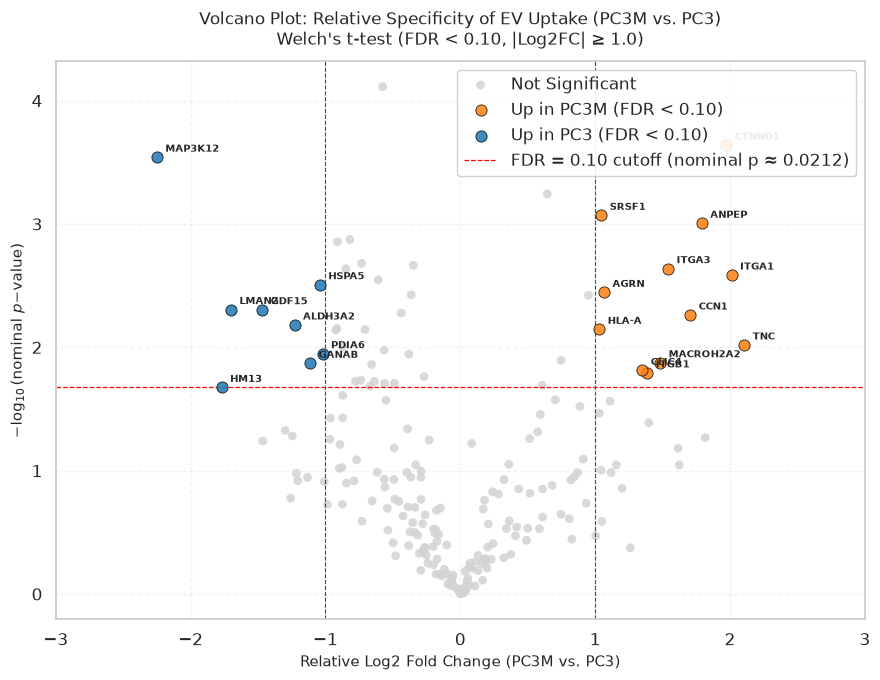

Total proteins passing FDR < 0.10 and |Log2FC| >= 1.0: 22

                                Gene    Log2FC   p_value   q_value             Significance
Master Protein Accessions                                                                  
O60716                        CTNND1  1.973426  0.000230  0.015249  Up in PC3M (FDR < 0.10)
Q12852                       MAP3K12 -2.249427  0.000288  0.015249   Up in PC3 (FDR < 0.10)
P15144                         ANPEP  1.791282  0.000988  0.029911  Up in PC3M (FDR < 0.10)
Q07955                         SRSF1  1.046582  0.000852  0.029911  Up in PC3M (FDR < 0.10)
P08572                        COL4A2  6.014406  0.001556  0.032989  Up in PC3M (FDR < 0.10)
P26006                         ITGA3  1.541898  0.002305  0.034981  Up in PC3M (FDR < 0.10)
P56199                         ITGA1  2.012386  0.002600  0.036741  Up in PC3M (FDR < 0.10)
P11021                         HSPA5 -1.040491  0.003112  0.038810   Up in PC3 (FDR < 0.10)
O00468               

In [38]:
method = "Welch's"

# 1. Define sample channels and extract group matrices
pc3_cols = ["norm_PC3_EV_R2", "norm_PC3_EV_R3"]
pc3m_cols = [
    "norm_PC3M_EV_R1",
    "norm_PC3M_EV_R2",
    "norm_PC3M_EV_R3",
    "norm_PC3M_EV_R4",
]

vals_pc3 = df_centered[pc3_cols].to_numpy(dtype=float)
vals_pc3m = df_centered[pc3m_cols].to_numpy(dtype=float)

# 2. Vectorized differential analysis (log2FC and Welch's t-test)
log2_fc = np.mean(vals_pc3m, axis=1) - np.mean(vals_pc3, axis=1)

# Vectorized Welch's t-test across all proteins simultaneously (axis=1)
_, p_values = stats.ttest_ind(vals_pc3m, vals_pc3, axis=1, equal_var=False)
p_values = np.nan_to_num(p_values, nan=1.0)

# 3. Assemble volcano table and map genes
if "Genes" in df_imputed.columns:
    gene_map = df_imputed.set_index("Master Protein Accessions")["Genes"]
    gene_series = gene_map.reindex(df_centered.index).values
else:
    gene_series = df_centered.index.values

# 4. Multiple testing correction (Benjamini-Hochberg)
fdr_threshold = 0.10
fc_threshold = 1.0

reject, q_values, _, _ = multipletests(
    p_values, alpha=fdr_threshold, method="fdr_bh"
)

volcano_df = pd.DataFrame(
    {
        "Accession": df_centered.index,
        "Gene": gene_series,
        "Log2FC": log2_fc,
        "p_value": p_values,
        "q_value": q_values,
        "neg_log10_p": -np.log10(p_values),
        "neg_log10_q": -np.log10(np.maximum(q_values, 1e-10)),
        "FDR_Significant": reject,
    },
    index=df_centered.index,
)

# 5. Significance classification and visualization
sig_up = volcano_df["FDR_Significant"] & (volcano_df["Log2FC"] >= fc_threshold)
sig_down = volcano_df["FDR_Significant"] & (volcano_df["Log2FC"] <= -fc_threshold)

volcano_df["Significance"] = np.select(
    [sig_up, sig_down],
    [
        f"Up in PC3M (FDR < {fdr_threshold:.2f})",
        f"Up in PC3 (FDR < {fdr_threshold:.2f})",
    ],
    default="Not Significant",
)

plot_volcano(
    volcano_df,
    fdr_threshold=fdr_threshold,
    fc_threshold=fc_threshold,
    method=method,
)

## 16. Empirical Bayes Moderated Differential Uptake Analysis

To account for low and unbalanced sample sizes ($n_1 = 2$ for PC3, $n_2 = 4$ for PC3M), differential expression was evaluated using an Empirical Bayes moderated $t$-test (Smyth, 2004, [Linear Models and Empirical Bayes Methods for Assessing Differential Expression in Microarray Experiments](https://doi.org/10.2202/1544-6115.1027)). Standard Student's or Welch's $t$-tests are prone to error in this setting, as low residual degrees of freedom ($d_g = n_1 + n_2 - 2 = 4$) produce unstable individual variance estimates. When sample variances are underestimated by chance, test statistics inflate and yield false positives.

The analysis was performed using the `limma` package via the following steps:

### 16.1. Linear Modeling and Contrasts

Log2-transformed normalized intensities for each protein $g$ were fitted using a linear model:


$$\mathbb{E}(y_g) = X\alpha_g$$


where $X$ is a design matrix without an intercept specifying group indicators (`PC3` and `PC3M`), and $\alpha_g$ contains the group mean log2 intensities. Differential uptake between conditions was extracted via the contrast:


$$\beta_g = C^T \alpha_g = \text{PC3M} - \text{PC3}$$


Ordinary least squares estimation yielded the contrast coefficient $\hat{\beta}_g$ ($\log_2\text{FC}$) and residual sample variance $s_g^2$ with $d_g = 4$ residual degrees of freedom.

### 16.2. Variance Shrinkage

To stabilize variance estimates, a hierarchical model was applied across all quantified proteins:


$$\frac{1}{\sigma_g^2} \sim \frac{1}{d_0 s_{0g}^2} \chi^2_{d_0}$$


Hyperparameters were estimated using the complete protein dataset:

* **Intensity-Dependent Trend (`trend = TRUE`):** The prior variance $s_{0g}^2 = f(\bar{y}_g)$ was modeled as a function of mean log2 intensity using regression splines to account for mean-dependent variance.


* **Outlier Weighting (`robust = TRUE`):** Prior degrees of freedom $d_0$ were estimated using robust empirical moments of log-residual variances (Phipson et al., 2016) to limit the influence of individual outliers on global hyperparameter estimates.
* **Posterior Variance:** The moderated variance $\tilde{s}_g^2$ was computed as:

$$\tilde{s}_g^2 = \frac{d_0 s_{0g}^2 + d_g s_g^2}{d_0 + d_g}$$



This contracts observed variances toward the intensity-dependent prior curve.



### 16.3. Test Statistics and Error Control

Significance was tested using the moderated $t$-statistic:


$$\tilde{t}_g = \frac{\hat{\beta}_g}{\tilde{s}_g \sqrt{v_g}}$$


where $v_g = \frac{1}{n_1} + \frac{1}{n_2} = \frac{1}{2} + \frac{1}{4} = 0.75$.

Under the null hypothesis ($H_0: \beta_g = 0$), $\tilde{t}_g$ follows a Student's $t$-distribution with $d_g + d_0$ degrees of freedom:


$$\tilde{t}_g \sim t_{d_g + d_0}$$

Nominal $p$-values were derived from the two-tailed $t_{d_g + d_0}$ distribution and adjusted for multiplicity using the Benjamini–Hochberg False Discovery Rate (FDR) procedure. Proteins with an adjusted $q < 0.10$ and $\vert{}\log_2\text{FC}\vert{} \ge 1.0$ were classified as differentially abundant.

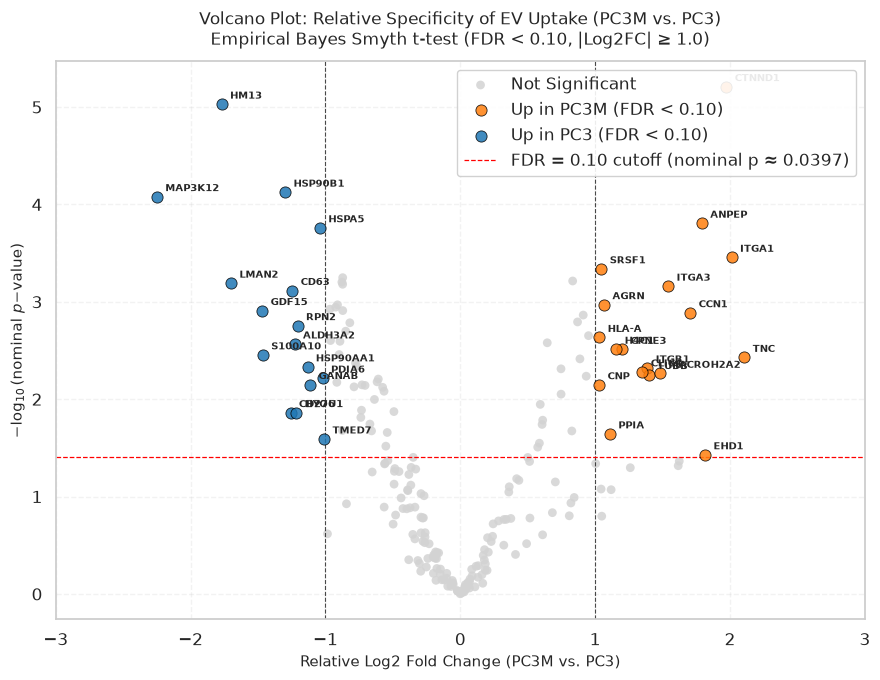

Total proteins passing FDR < 0.10 and |Log2FC| >= 1.0: 37

             Gene    Log2FC   p_value   q_value             Significance
O60716     CTNND1  1.973426  0.000006  0.000771  Up in PC3M (FDR < 0.10)
P21980       TGM2  4.126660  0.000011  0.000771  Up in PC3M (FDR < 0.10)
Q8TCT9       HM13 -1.768839  0.000009  0.000771   Up in PC3 (FDR < 0.10)
P08572     COL4A2  6.014406  0.000050  0.002657  Up in PC3M (FDR < 0.10)
P14625    HSP90B1 -1.298344  0.000075  0.002944   Up in PC3 (FDR < 0.10)
Q12852    MAP3K12 -2.249427  0.000083  0.002944   Up in PC3 (FDR < 0.10)
P15144      ANPEP  1.791282  0.000156  0.004611  Up in PC3M (FDR < 0.10)
P11021      HSPA5 -1.040491  0.000174  0.004611   Up in PC3 (FDR < 0.10)
P56199      ITGA1  2.012386  0.000350  0.007682  Up in PC3M (FDR < 0.10)
P02751        FN1  3.761799  0.000362  0.007682  Up in PC3M (FDR < 0.10)
Q12907      LMAN2 -1.699602  0.000645  0.008639   Up in PC3 (FDR < 0.10)
Q07955      SRSF1  1.046582  0.000459  0.008639  Up in PC3M (FDR 

In [39]:
method = "Empirical Bayes Smyth"

# 1. Experimental layout and subset extraction
pc3_cols = ["norm_PC3_EV_R2", "norm_PC3_EV_R3"]
pc3m_cols = [
    "norm_PC3M_EV_R1",
    "norm_PC3M_EV_R2",
    "norm_PC3M_EV_R3",
    "norm_PC3M_EV_R4",
]
all_cols = pc3_cols + pc3m_cols
df_sub = df_centered[all_cols].copy()
groups = ["PC3"] * len(pc3_cols) + ["PC3M"] * len(pc3m_cols)

# 2. R limma execution
with localconverter(ro.default_converter + pandas2ri.converter):
    ro.globalenv["expr_data"] = ro.conversion.py2rpy(df_sub)

ro.globalenv["groups"] = ro.StrVector(groups)

ro.r(
    """
suppressPackageStartupMessages(library(limma))

group_factor <- factor(groups, levels = c("PC3", "PC3M"))
design <- model.matrix(~ 0 + group_factor)
colnames(design) <- levels(group_factor)

fit <- lmFit(expr_data, design)
contrast_matrix <- makeContrasts(PC3M_vs_PC3 = PC3M - PC3, levels = design)
fit2 <- contrasts.fit(fit, contrast_matrix)
fit_eb <- eBayes(fit2, trend = TRUE, robust = TRUE)

res_table <- topTable(
    fit_eb,
    coef = "PC3M_vs_PC3",
    adjust.method = "BH",
    number = Inf,
    sort.by = "none"
)

trend_data <- data.frame(
    Amean = fit_eb$Amean,
    sigma_raw = fit_eb$sigma,
    sigma_post = sqrt(fit_eb$s2.post),
    sigma_prior = sqrt(fit_eb$s2.prior)
)
"""
)

with localconverter(ro.default_converter + pandas2ri.converter):
    limma_res = ro.conversion.rpy2py(ro.globalenv["res_table"])
    trend_df = ro.conversion.rpy2py(ro.globalenv["trend_data"])

# 3. Assemble volcano table
if "Genes" in df_imputed.columns:
    gene_map = df_imputed.set_index("Master Protein Accessions")["Genes"]
    gene_series = gene_map.reindex(limma_res.index).values
else:
    gene_series = limma_res.index.values

p_values = limma_res["P.Value"].fillna(1.0).values
q_values = limma_res["adj.P.Val"].fillna(1.0).values

volcano_df = pd.DataFrame(
    {
        "Accession": limma_res.index,
        "Gene": gene_series,
        "Log2FC": limma_res["logFC"].values,
        "p_value": p_values,
        "q_value": q_values,
        "t_stat": limma_res["t"].values,
        "B_stat": limma_res["B"].values,
        "neg_log10_p": -np.log10(p_values),
        "neg_log10_q": -np.log10(np.maximum(q_values, 1e-10)),
    },
    index=limma_res.index,
)

# 4. Significance classification and visualization
fdr_threshold = 0.10
fc_threshold = 1.0

volcano_df["FDR_Significant"] = volcano_df["q_value"] < fdr_threshold

sig_up = volcano_df["FDR_Significant"] & (volcano_df["Log2FC"] >= fc_threshold)
sig_down = volcano_df["FDR_Significant"] & (volcano_df["Log2FC"] <= -fc_threshold)

volcano_df["Significance"] = np.select(
    [sig_up, sig_down],
    [f"Up in PC3M (FDR < {fdr_threshold:.2f})", f"Up in PC3 (FDR < {fdr_threshold:.2f})"],
    default="Not Significant",
)

plot_volcano(
    volcano_df,
    fdr_threshold=fdr_threshold,
    fc_threshold=fc_threshold,
    method=method,
)

**Mean-variance relationship and empirical Bayes variance shrinkage.**

The scatter plot displays the dependence of protein-level residual standard deviation on mean abundance ($\text{Amean}$, $\log_2$ scale) across the proteomic dataset. Individual sample standard deviations ($s_g$, grey points) show high dispersion, particularly in regions with small sample variance where estimates approach zero due to limited sample size. The solid red curve represents the estimated prior variance trend ($s_{0g}$, `trend = TRUE`), modeled via a cubic regression spline to account for intensity-dependent technical variance across the dynamic range. Moderated standard deviations ($\tilde{s}_g$, blue points) represent the posterior values obtained after empirical Bayes moderation (`eBayes(..., robust = TRUE)`). The shrinkage adjusts low-variance artifacts upward toward the expected trend and pulls extreme positive outliers downward, stabilizing the denominator for downstream moderated $t$-statistic calculations.

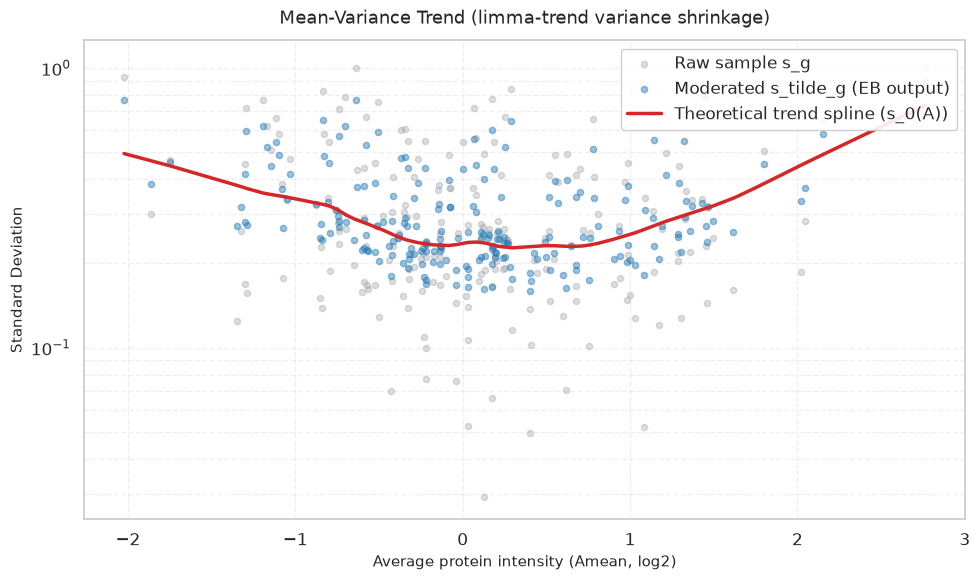

In [40]:
trend_df = trend_df.sort_values(by="Amean").reset_index(drop=True)
plt.figure(figsize=(10, 6))

# 1. Raw sample points for each protein (raw noise s_g)
plt.scatter(
    trend_df["Amean"],
    trend_df["sigma_raw"],
    color="#9aa0a6",
    alpha=0.35,
    s=20,
    label="Raw sample s_g",
)

# 2. Shrinkage/moderation result (moderated s_tilde_g)
plt.scatter(
    trend_df["Amean"],
    trend_df["sigma_post"],
    color="#1f77b4",
    alpha=0.45,
    s=20,
    label="Moderated s_tilde_g (EB output)",
)

# 3. Theoretical trend spline (limma-trend)
plt.plot(
    trend_df["Amean"],
    trend_df["sigma_prior"],
    color="#d62728",
    linewidth=2.5,
    label="Theoretical trend spline (s_0(A))",
)

plt.title("Mean-Variance Trend (limma-trend variance shrinkage)", fontsize=13, pad=12)
plt.xlabel("Average protein intensity (Amean, log2)", fontsize=11)
plt.ylabel("Standard Deviation", fontsize=11)
plt.yscale("log")  # log scale makes the shift distinct and compact
plt.legend(frameon=True, facecolor="white", framealpha=0.9, loc="upper right")
plt.grid(True, which="both", linestyle="--", alpha=0.3)

plt.tight_layout()
plt.show()

## 17. Hierarchical Clustering of Significant Markers

To evaluate whether the identified differentially abundant proteins capture coherent multivariate differences between the conditions without model supervision, we performed unsupervised hierarchical clustering on the significant hits (FDR < 0.10, $\vert{}\log_2\text{FC}\vert{} \ge 1.0$).

### Methodology
* **Standardization:** Normalized intensity profiles were standardized across samples for each protein using row-wise $Z$-scores ($z = (x - \mu) / \sigma$), centering each protein's mean at 0 with unit variance to allow direct visual comparison across different baseline abundance levels.
* **Clustering Metric and Linkage:** Both samples (columns) and proteins (rows) were clustered using Euclidean distance and average linkage (`method="average"`). 

### Interpretation Goals
* **Sample Separation:** Because the clustering algorithm operates in an unsupervised manner without access to group labels, the column dendrogram serves as an unbiased test of phenotype separation. A clean bifurcation of the biological replicates into distinct `PC3` and `PC3M` clades confirms that the selected signature robustly reflects phenotype-specific EV uptake rather than technical batch effects.
* **Coregulated Modules:** The row dendrogram groups proteins exhibiting parallel uptake patterns, highlighting clusters of co-enriched or co-depleted factors that may function together in target cellular processes.

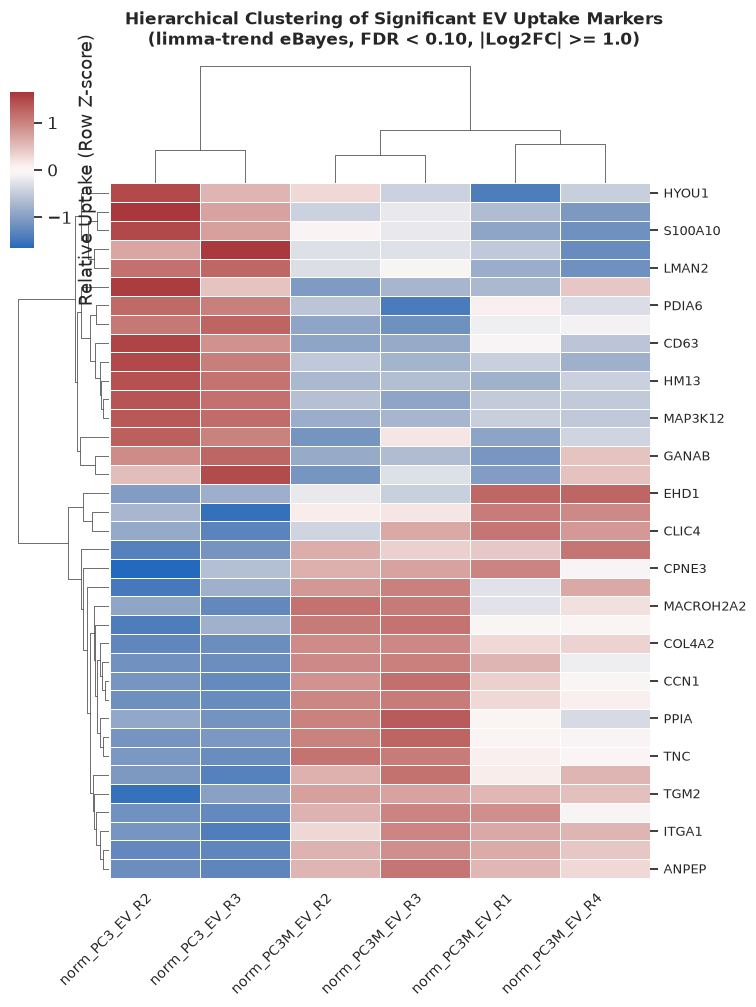

In [41]:
# 1. Extract significant markers (limma FDR hits)
sig_hits = volcano_df[volcano_df["Significance"] != "Not Significant"]
key_markers = sig_hits.index.tolist()

# Select only experimental channels of interest (EV samples)
channels = pc3_cols + pc3m_cols
heatmap_data = df_centered.loc[key_markers, channels].copy()

# Map UniProt Accessions to Genes if available
if "Gene" in volcano_df.columns:
    gene_labels = volcano_df.loc[key_markers, "Gene"].fillna(
        pd.Series(key_markers, index=key_markers)
    )
    heatmap_data.index = gene_labels.values

# 2. Plot Seaborn Clustermap
g = sns.clustermap(
    heatmap_data,
    cmap="vlag",
    center=0,
    z_score=0,  # standardize across rows (proteins)
    col_cluster=True,  # cluster samples
    row_cluster=True,  # cluster proteins
    figsize=(8, max(6, len(key_markers) * 0.28)),  # dynamic height scaling
    dendrogram_ratio=(0.15, 0.15),
    cbar_pos=(0.02, 0.8, 0.03, 0.15),
    cbar_kws={"label": "Relative Uptake (Row Z-score)"},
    linewidths=0.5,
    linecolor="white",
    method="average",
)

# Figure styling and labels
g.figure.suptitle(
    f"Hierarchical Clustering of Significant EV Uptake Markers\n"
    f"(limma-trend eBayes, FDR < {fdr_threshold:.2f}, |Log2FC| >= {fc_threshold:.1f})",
    y=1.03,
    fontsize=12,
    fontweight="bold",
)
plt.setp(g.ax_heatmap.get_xticklabels(), rotation=45, ha="right", fontsize=10)
plt.setp(g.ax_heatmap.get_yticklabels(), fontsize=9)

plt.show()